In [2]:
import zipfile
import os

zip_path = "../data/Chicago Datasets.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(".")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [3]:
import os

for file in os.listdir("."):
    print(file)

.ipynb_checkpoints
Chicago Datasets
Chicago_Crime_Capstone.ipynb


In [4]:
import os

print("Current working directory:", os.getcwd())

print("\nDataset files:")

for file in os.listdir("Chicago Datasets"):
    print(file)

Current working directory: C:\Users\prashant.k.saraswat\Downloads\Chicago-Crime-Capstone\notebooks

Dataset files:
chicago_city_community.csv
chicago_crime_dataset.csv
chicago_crime_dataset_repaired.csv
chicago_district_ps_info.csv
chicago_police_beat_info.csv
chicago_ward_offices.csv
iucr_codes.csv
iucr_codes.csv.csv


In [5]:
import os

old_name = "Chicago Datasets/iucr_codes.csv.csv"
new_name = "Chicago Datasets/iucr_codes.csv"

if os.path.exists(old_name) and not os.path.exists(new_name):
    os.rename(old_name, new_name)
    print("IUCR filename corrected!")

elif os.path.exists(new_name):
    print("Correct IUCR file already exists!")

else:
    print("IUCR file not found!")

Correct IUCR file already exists!


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
from pathlib import Path

# Original dataset
file_path = Path("Chicago Datasets/chicago_crime_dataset.csv")

# Read all CSV lines
with open(file_path, "r", encoding="utf-8") as file:
    lines = file.readlines()

# Identify and repair unclosed quotation marks
repaired_lines = []

for line in lines:
    if line.count('"') % 2 != 0:
        line = line.rstrip("\r\n") + '"\n'

    repaired_lines.append(line)

# Save corrected dataset separately
cleaned_path = Path("Chicago Datasets/chicago_crime_dataset_repaired.csv")

with open(cleaned_path, "w", encoding="utf-8", newline="") as file:
    file.writelines(repaired_lines)

print("CSV formatting repaired successfully!")

CSV formatting repaired successfully!


In [8]:
df = pd.read_csv(
    "Chicago Datasets/chicago_crime_dataset_repaired.csv",
    low_memory=False
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (498, 20)


In [9]:
df.tail(2)

,id,case_number,date,block,iucr_code,location_desc,arrest,domestic,beat_num,district_code,ward_no,community_code,fbi_code,x_coordinate,y_coordinate,year,date_of_update,latitude,longitude,location
496,10510050,HZ251541,5/4/2016,071XX S MORGAN ST,1310,RESIDENCE,False,False,733,7,17,68,14,1170880.0,1857391.0,2016,5/11/2016,41.764155,-87.649243,"(41.764154883, -87.649243025)"
497,10510051,HZ251540,5/4/2016,071XX S MORGAN ST,1310,RESIDENCE,False,False,733,7,17,68,14,1170880.0,1857391.0,2016,5/11/2016,41.764155,-87.649243,"(41.764154883, -87.649243025)"


In [10]:
df.head(10)

,id,case_number,date,block,iucr_code,location_desc,arrest,domestic,beat_num,district_code,ward_no,community_code,fbi_code,x_coordinate,y_coordinate,year,date_of_update,latitude,longitude,location
0,10508693,HZ250496,5/3/2016,013XX S SAWYER AVE,486,APARTMENT,True,True,1022,10,24,29,08B,1154907.0,1893681.0,2016,5/10/2016,41.864073,-87.706819,"(41.864073157, -87.706818608)"
1,10508695,HZ250409,5/3/2016,061XX S DREXEL AVE,486,RESIDENCE,False,True,313,3,20,42,08B,1183066.0,1864330.0,2016,5/10/2016,41.782922,-87.604363,"(41.782921527, -87.60436317)"
2,10508697,HZ250503,5/3/2016,053XX W CHICAGO AVE,470,STREET,False,False,1524,15,37,25,24,1140789.0,1904819.0,2016,5/10/2016,41.894908,-87.758372,"(41.894908283, -87.758371958)"
3,10508698,HZ250424,5/3/2016,049XX W FULTON ST,460,SIDEWALK,False,False,1532,15,28,25,08B,1143223.0,1901475.0,2016,5/10/2016,41.885687,-87.749516,"(41.885686845, -87.749515983)"
4,10508699,HZ250455,5/3/2016,003XX N LOTUS AVE,820,RESIDENCE,False,True,1523,15,28,25,6,1139890.0,1901675.0,2016,5/10/2016,41.886297,-87.761751,"(41.886297242, -87.761750709)"
5,10508702,HZ250447,5/3/2016,082XX S MARYLAND AVE,041A,STREET,False,False,631,6,8,44,04B,1183336.0,1850642.0,2016,5/10/2016,41.745354,-87.603799,"(41.745354023, -87.603798903)"
6,10508703,HZ250489,5/3/2016,027XX S STATE ST,460,CHA HALLWAY/STAIRWELL/ELEVATOR,False,False,133,1,3,35,08B,1176730.0,1886544.0,2016,5/10/2016,41.844024,-87.626923,"(41.844023772, -87.626923253)"
7,10508704,HZ250514,5/3/2016,002XX E 46TH ST,460,RESIDENCE PORCH/HALLWAY,False,False,215,2,3,38,08B,1178514.0,1874573.0,2016,5/10/2016,41.811134,-87.620741,"(41.811133958, -87.62074077)"
8,10508709,HZ250523,5/3/2016,014XX W DEVON AVE,460,SIDEWALK,False,False,2432,24,40,1,08B,1165696.0,1942616.0,2016,5/10/2016,41.998131,-87.665814,"(41.99813061, -87.665814038)"
9,10508982,HZ250667,5/3/2016,069XX S ASHLAND AVE,486,STREET,False,True,735,7,17,67,08B,1166876.0,1858796.0,2016,5/10/2016,41.768097,-87.663879,"(41.768096835, -87.663878589)"


In [11]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 498
Total Columns: 20


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 498 entries, 0 to 497
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              498 non-null    int64  
 1   case_number     498 non-null    str    
 2   date            498 non-null    str    
 3   block           498 non-null    str    
 4   iucr_code       498 non-null    str    
 5   location_desc   494 non-null    str    
 6   arrest          498 non-null    bool   
 7   domestic        498 non-null    bool   
 8   beat_num        498 non-null    int64  
 9   district_code   498 non-null    int64  
 10  ward_no         498 non-null    int64  
 11  community_code  498 non-null    int64  
 12  fbi_code        498 non-null    str    
 13  x_coordinate    469 non-null    float64
 14  y_coordinate    469 non-null    float64
 15  year            498 non-null    int64  
 16  date_of_update  498 non-null    str    
 17  latitude        469 non-null    float64
 18  l

In [13]:
df.dtypes


id                  int64
case_number           str
date                  str
block                 str
iucr_code             str
location_desc         str
arrest               bool
domestic             bool
beat_num            int64
district_code       int64
ward_no             int64
community_code      int64
fbi_code              str
x_coordinate      float64
y_coordinate      float64
year                int64
date_of_update        str
latitude          float64
longitude         float64
location              str
dtype: object

In [14]:
for col in df.columns:
    print(col)

id
case_number
date
block
iucr_code
location_desc
arrest
domestic
beat_num
district_code
ward_no
community_code
fbi_code
x_coordinate
y_coordinate
year
date_of_update
latitude
longitude
location


In [15]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,498.0,NaN,NaN,NaN,10442946.73494,812499.754132,20859.0,10509096.75,10509688.5,10509949.75,10516300.0
case_number,498,498,HZ250496,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,498,46,5/4/2016,298,NaN,NaN,NaN,NaN,NaN,NaN,NaN
block,498,475,011XX W JACKSON BLVD,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
iucr_code,498,97,486,43,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location_desc,494,47,STREET,105,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrest,498,2,False,374,NaN,NaN,NaN,NaN,NaN,NaN,NaN
domestic,498,2,False,430,NaN,NaN,NaN,NaN,NaN,NaN,NaN
beat_num,498.0,NaN,NaN,NaN,1115.927711,696.580838,111.0,533.0,1023.0,1632.75,2535.0
district_code,498.0,NaN,NaN,NaN,10.925703,6.95751,1.0,5.0,10.0,16.0,25.0


In [16]:
missing_values = df.isnull().sum()

missing_percentage = (
    missing_values / len(df)
) * 100

missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

,Missing Values,Missing Percentage
location,29,5.823293
y_coordinate,29,5.823293
longitude,29,5.823293
latitude,29,5.823293
x_coordinate,29,5.823293
location_desc,4,0.803213
case_number,0,0.000000
id,0,0.000000
block,0,0.000000
date,0,0.000000


In [17]:

# Calculate missing values and percentages using NumPy

missing_array = df.isnull().to_numpy()
missing_counts = np.sum(missing_array, axis=0)
missing_percentage = (
    missing_counts / len(df)
) * 100

numpy_missing_summary = pd.DataFrame({
    'Missing Values': missing_counts,
    'Missing Percentage': missing_percentage
}, index=df.columns)

print("Missing Value Analysis using NumPy:")
display(
    numpy_missing_summary.sort_values(
        by='Missing Percentage',
        ascending=False
    )
)

Missing Value Analysis using NumPy:


,Missing Values,Missing Percentage
location,29,5.823293
y_coordinate,29,5.823293
longitude,29,5.823293
latitude,29,5.823293
x_coordinate,29,5.823293
location_desc,4,0.803213
case_number,0,0.000000
id,0,0.000000
block,0,0.000000
date,0,0.000000


In [18]:
columns_to_drop = missing_summary[
    missing_summary['Missing Percentage'] > 50
].index.tolist()

print("Columns having more than 50% missing values:")
print(columns_to_drop)

if len(columns_to_drop) == 0:
    print("No columns need to be dropped.")

Columns having more than 50% missing values:
[]
No columns need to be dropped.


In [19]:
# Fill missing categorical descriptions

df['location_desc'] = df['location_desc'].fillna('UNKNOWN')

# Verify missing values after treatment

print(df.isnull().sum())

id                 0
case_number        0
date               0
block              0
iucr_code          0
location_desc      0
arrest             0
domestic           0
beat_num           0
district_code      0
ward_no            0
community_code     0
fbi_code           0
x_coordinate      29
y_coordinate      29
year               0
date_of_update     0
latitude          29
longitude         29
location          29
dtype: int64


In [20]:
print("Total columns:", len(df.columns))

for col in df.columns:
    print(col)

Total columns: 20
id
case_number
date
block
iucr_code
location_desc
arrest
domestic
beat_num
district_code
ward_no
community_code
fbi_code
x_coordinate
y_coordinate
year
date_of_update
latitude
longitude
location


In [21]:
df['date'] = pd.to_datetime(
    df['date'],
    format='mixed',
    errors='coerce'
)

print("Date conversion completed!")

print("\nDate column data type:")
print(df['date'].dtype)

print("\nFirst 10 dates:")
display(df['date'].head(10))

print("\nInvalid or missing dates:", df['date'].isna().sum())

Date conversion completed!

Date column data type:
datetime64[us]

First 10 dates:


0   2016-05-03
1   2016-05-03
2   2016-05-03
3   2016-05-03
4   2016-05-03
5   2016-05-03
6   2016-05-03
7   2016-05-03
8   2016-05-03
9   2016-05-03
Name: date, dtype: datetime64[us]


Invalid or missing dates: 0


In [22]:
# Identify invalid dates

invalid_dates = df['date'].isnull().sum()

print("Invalid or missing dates:", invalid_dates)

Invalid or missing dates: 0


In [23]:
# Identify categorical columns

categorical_columns = df.select_dtypes(
    include=['object']
).columns

print("Categorical columns:")
print(categorical_columns.tolist())


Categorical columns:
['case_number', 'block', 'iucr_code', 'location_desc', 'fbi_code', 'date_of_update', 'location']


C:\Users\prashant.k.saraswat\AppData\Local\Temp\ipykernel_25040\2740774226.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [24]:
# Clean categorical columns

for col in categorical_columns:
    df[col] = df[col].astype('string').str.strip().str.upper()

print("Categorical fields standardized successfully!")

Categorical fields standardized successfully!


In [25]:
# Extract Year, Month and DayOfWeek

df['Year'] = df['date'].dt.year

df['Month'] = df['date'].dt.month

df['DayOfWeek'] = df['date'].dt.day_name()

df[['date', 'Year', 'Month', 'DayOfWeek']].head(10)

,date,Year,Month,DayOfWeek
0,2016-05-03,2016,5,Tuesday
1,2016-05-03,2016,5,Tuesday
2,2016-05-03,2016,5,Tuesday
3,2016-05-03,2016,5,Tuesday
4,2016-05-03,2016,5,Tuesday
5,2016-05-03,2016,5,Tuesday
6,2016-05-03,2016,5,Tuesday
7,2016-05-03,2016,5,Tuesday
8,2016-05-03,2016,5,Tuesday
9,2016-05-03,2016,5,Tuesday


In [26]:
print("Updated dataset shape:", df.shape)

print("\nUpdated columns:")
print(df.columns.tolist())

print("\nUpdated data types:")
print(df.dtypes)

Updated dataset shape: (498, 23)

Updated columns:
['id', 'case_number', 'date', 'block', 'iucr_code', 'location_desc', 'arrest', 'domestic', 'beat_num', 'district_code', 'ward_no', 'community_code', 'fbi_code', 'x_coordinate', 'y_coordinate', 'year', 'date_of_update', 'latitude', 'longitude', 'location', 'Year', 'Month', 'DayOfWeek']

Updated data types:
id                         int64
case_number               string
date              datetime64[us]
block                     string
iucr_code                 string
location_desc             string
arrest                      bool
domestic                    bool
beat_num                   int64
district_code              int64
ward_no                    int64
community_code             int64
fbi_code                  string
x_coordinate             float64
y_coordinate             float64
year                       int64
date_of_update            string
latitude                 float64
longitude                float64
location       

In [27]:
# Load IUCR supporting dataset

iucr_df = pd.read_csv(
    "Chicago Datasets/iucr_codes.csv"
)

print("IUCR dataset shape:", iucr_df.shape)

print("\nIUCR columns:")
print(iucr_df.columns.tolist())

print("\nFirst 10 records:")
display(iucr_df.head(10))

print("\nData types:")
print(iucr_df.dtypes)

IUCR dataset shape: (410, 4)

IUCR columns:
['IUCR', 'PRIMARY_TYPE ', 'DESCRIPTION', 'INDEX CODE']

First 10 records:


,IUCR,PRIMARY_TYPE,DESCRIPTION,INDEX CODE
0,110,HOMICIDE,FIRST DEGREE MURDER,I
1,130,HOMICIDE,SECOND DEGREE MURDER,I
2,141,HOMICIDE,INVOLUNTARY MANSLAUGHTER,N
3,142,HOMICIDE,RECKLESS HOMICIDE,N
4,261,CRIMINAL SEXUAL ASSAULT,AGGRAVATED - HANDGUN,I
5,262,CRIMINAL SEXUAL ASSAULT,AGGRAVATED - OTHER FIREARM,I
6,263,CRIMINAL SEXUAL ASSAULT,AGGRAVATED - KNIFE / CUTTING INSTRUMENT,I
7,264,CRIMINAL SEXUAL ASSAULT,AGGRAVATED - OTHER DANGEROUS WEAPON,I
8,265,CRIMINAL SEXUAL ASSAULT,AGGRAVATED - OTHER,I
9,266,CRIMINAL SEXUAL ASSAULT,PREDATORY,I



Data types:
IUCR             str
PRIMARY_TYPE     str
DESCRIPTION      str
INDEX CODE       str
dtype: object


In [28]:
print(
    "Duplicate IUCR codes:",
    iucr_df['IUCR'].duplicated().sum()
)

Duplicate IUCR codes: 0


In [29]:
# Remove whitespace from column names

iucr_df.columns = iucr_df.columns.str.strip()

print("Updated IUCR columns:")
print(iucr_df.columns.tolist())

Updated IUCR columns:
['IUCR', 'PRIMARY_TYPE', 'DESCRIPTION', 'INDEX CODE']


In [30]:
# Standardize join keys

df['iucr_code'] = df['iucr_code'].astype(str).str.strip()
iucr_df['IUCR'] = iucr_df['IUCR'].astype(str).str.strip()

# Check duplicate IUCR codes

print("Duplicate IUCR codes:",
      iucr_df['IUCR'].duplicated().sum())

Duplicate IUCR codes: 0


In [31]:
# Merge crime dataset with IUCR classification dataset

df = df.merge(
    iucr_df[['IUCR', 'PRIMARY_TYPE', 'DESCRIPTION']],
    left_on='iucr_code',
    right_on='IUCR',
    how='left'
)

# Rename columns to assessment-friendly names

df.rename(columns={
    'PRIMARY_TYPE': 'primary_type',
    'DESCRIPTION': 'description'
}, inplace=True)

# Remove redundant IUCR column

df.drop(columns=['IUCR'], inplace=True)

print("Datasets merged successfully!")
print("Updated shape:", df.shape)

Datasets merged successfully!
Updated shape: (498, 25)


C:\Users\prashant.k.saraswat\AppData\Local\Temp\ipykernel_25040\798221754.py:12: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={
C:\Users\prashant.k.saraswat\AppData\Local\Temp\ipykernel_25040\798221754.py:19: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['IUCR'], inplace=True)


In [32]:
df[['iucr_code', 'primary_type', 'description']].head(15)

,iucr_code,primary_type,description
0,486,BATTERY,DOMESTIC BATTERY SIMPLE
1,486,BATTERY,DOMESTIC BATTERY SIMPLE
2,470,PUBLIC PEACE VIOLATION,RECKLESS CONDUCT
3,460,BATTERY,SIMPLE
4,820,THEFT,$500 AND UNDER
5,041A,BATTERY,AGGRAVATED - HANDGUN
6,460,BATTERY,SIMPLE
7,460,BATTERY,SIMPLE
8,460,BATTERY,SIMPLE
9,486,BATTERY,DOMESTIC BATTERY SIMPLE


In [33]:
print("Missing Primary Types:",
      df['primary_type'].isnull().sum())

print("Missing Descriptions:",
      df['description'].isnull().sum())

Missing Primary Types: 0
Missing Descriptions: 0


In [34]:
print("Total crime records:", len(df))
print("Unique crime records:", df['id'].nunique())

Total crime records: 498
Unique crime records: 498


In [35]:
import os

os.makedirs("../reports", exist_ok=True)

df.to_csv(
    "../reports/chicago_crime_cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [36]:
print("Dataset shape:", df.shape)

print("\nUnique crime types:",
      df['primary_type'].nunique())

print("\nTop 10 crime categories:")
print(df['primary_type'].value_counts().head(10))

print("\nDate range:")
print(df['date'].min(), "to", df['date'].max())

Dataset shape: (498, 25)

Unique crime types: 23

Top 10 crime categories:
primary_type
THEFT                  105
BATTERY                 85
CRIMINAL DAMAGE         49
OTHER OFFENSE           39
DECEPTIVE PRACTICE      38
ASSAULT                 35
NARCOTICS               32
ROBBERY                 30
CRIMINAL TRESPASS       17
MOTOR VEHICLE THEFT     16
Name: count, dtype: int64

Date range:
2012-01-01 00:00:00 to 2016-05-04 00:00:00


In [37]:
import os

print("Current directory:", os.getcwd())

print("\nProject folders:")
print(os.listdir(".."))

Current directory: C:\Users\prashant.k.saraswat\Downloads\Chicago-Crime-Capstone\notebooks

Project folders:
['.gitignore', '.ipynb_checkpoints', '.vscode', 'app', 'app.py', 'data', 'notebooks', 'README.md', 'reports', 'requirements.txt', 'venv']


In [38]:
import sqlite3
import os

# Create database inside reports folder
db_path = os.path.join(
    "..", "reports", "chicago_crime.db"
)

conn = sqlite3.connect(db_path)

print("SQLite database connected successfully!")
print("Database location:", os.path.abspath(db_path))

SQLite database connected successfully!
Database location: C:\Users\prashant.k.saraswat\Downloads\Chicago-Crime-Capstone\reports\chicago_crime.db


In [39]:
df.drop(columns=['Year'], inplace=True)

print("Updated columns:")
print(df.columns.tolist())

C:\Users\prashant.k.saraswat\AppData\Local\Temp\ipykernel_25040\3416998354.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['Year'], inplace=True)


Updated columns:
['id', 'case_number', 'date', 'block', 'iucr_code', 'location_desc', 'arrest', 'domestic', 'beat_num', 'district_code', 'ward_no', 'community_code', 'fbi_code', 'x_coordinate', 'y_coordinate', 'year', 'date_of_update', 'latitude', 'longitude', 'location', 'Month', 'DayOfWeek', 'primary_type', 'description']


In [40]:
# Create crime table from cleaned dataset

df.to_sql(
    "crime",
    conn,
    if_exists="replace",
    index=False
)

print("Crime table created successfully!")

Crime table created successfully!


In [41]:
import pandas as pd

# Load previously cleaned dataset
df = pd.read_csv(
    "../reports/chicago_crime_cleaned.csv"
)

print("Cleaned dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Cleaned dataset loaded successfully!
Dataset shape: (498, 25)


,id,case_number,date,block,iucr_code,location_desc,arrest,domestic,beat_num,district_code,ward_no,community_code,fbi_code,x_coordinate,y_coordinate,year,date_of_update,latitude,longitude,location,Year,Month,DayOfWeek,primary_type,description
0,10508693,HZ250496,2016-05-03,013XX S SAWYER AVE,486,APARTMENT,True,True,1022,10,24,29,08B,1154907.0,1893681.0,2016,5/10/2016,41.864073,-87.706819,"(41.864073157, -87.706818608)",2016,5,Tuesday,BATTERY,DOMESTIC BATTERY SIMPLE
1,10508695,HZ250409,2016-05-03,061XX S DREXEL AVE,486,RESIDENCE,False,True,313,3,20,42,08B,1183066.0,1864330.0,2016,5/10/2016,41.782922,-87.604363,"(41.782921527, -87.60436317)",2016,5,Tuesday,BATTERY,DOMESTIC BATTERY SIMPLE
2,10508697,HZ250503,2016-05-03,053XX W CHICAGO AVE,470,STREET,False,False,1524,15,37,25,24,1140789.0,1904819.0,2016,5/10/2016,41.894908,-87.758372,"(41.894908283, -87.758371958)",2016,5,Tuesday,PUBLIC PEACE VIOLATION,RECKLESS CONDUCT
3,10508698,HZ250424,2016-05-03,049XX W FULTON ST,460,SIDEWALK,False,False,1532,15,28,25,08B,1143223.0,1901475.0,2016,5/10/2016,41.885687,-87.749516,"(41.885686845, -87.749515983)",2016,5,Tuesday,BATTERY,SIMPLE
4,10508699,HZ250455,2016-05-03,003XX N LOTUS AVE,820,RESIDENCE,False,True,1523,15,28,25,6,1139890.0,1901675.0,2016,5/10/2016,41.886297,-87.761751,"(41.886297242, -87.761750709)",2016,5,Tuesday,THEFT,$500 AND UNDER


In [42]:
# Remove redundant extracted Year column
df = df.drop(columns=['Year'])

print("Redundant Year column removed!")
print("Current columns:", df.columns.tolist())

Redundant Year column removed!
Current columns: ['id', 'case_number', 'date', 'block', 'iucr_code', 'location_desc', 'arrest', 'domestic', 'beat_num', 'district_code', 'ward_no', 'community_code', 'fbi_code', 'x_coordinate', 'y_coordinate', 'year', 'date_of_update', 'latitude', 'longitude', 'location', 'Month', 'DayOfWeek', 'primary_type', 'description']


In [43]:
df.to_sql(
    "crime",
    conn,
    if_exists="replace",
    index=False
)

print("Crime table created successfully!")

Crime table created successfully!


In [44]:
# Compare original year with extracted year

date_year = pd.to_datetime(df['date']).dt.year

mismatches = (df['year'] != date_year).sum()

print("Year mismatches:", mismatches)

Year mismatches: 0


In [45]:
df.to_sql(
    "crime",
    conn,
    if_exists="replace",
    index=False
)

print("Crime table created successfully!")

Crime table created successfully!


In [46]:
cursor = conn.cursor()

cursor.execute("SELECT COUNT(*) FROM crime")

print("Total records inserted:", cursor.fetchone()[0])

Total records inserted: 498


In [47]:
query = """
SELECT
    year,
    COUNT(*) AS total_crimes
FROM crime
GROUP BY year
ORDER BY year;
"""

result = pd.read_sql_query(query, conn)

print("Crime count per year:")
display(result)

Crime count per year:


,year,total_crimes
0,2012,2
1,2013,1
2,2014,1
3,2015,4
4,2016,490


In [48]:
query = """
SELECT
    primary_type,
    COUNT(*) AS crime_count,
    ROUND(
        COUNT(*) * 100.0 / (SELECT COUNT(*) FROM crime),
        2
    ) AS percentage
FROM crime
GROUP BY primary_type
ORDER BY crime_count DESC
LIMIT 5;
"""

display(pd.read_sql_query(query, conn))

,primary_type,crime_count,percentage
0,THEFT,105,21.08
1,BATTERY,85,17.07
2,CRIMINAL DAMAGE,49,9.84
3,OTHER OFFENSE,39,7.83
4,DECEPTIVE PRACTICE,38,7.63


In [49]:
query = """
SELECT
    year,
    SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END) AS arrest_count
FROM crime
GROUP BY year
ORDER BY year;
"""

display(pd.read_sql_query(query, conn))

,year,arrest_count
0,2012,2
1,2013,1
2,2014,0
3,2015,2
4,2016,119


In [50]:
cursor = conn.cursor()

# View 1: Yearly crime summary

cursor.execute("""
CREATE VIEW IF NOT EXISTS vw_crime_yearly AS
SELECT
    year,
    COUNT(*) AS total_crimes,
    SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END)
        AS arrest_count
FROM crime
GROUP BY year;
""")

# View 2: Crime category summary

cursor.execute("""
CREATE VIEW IF NOT EXISTS vw_crime_by_category AS
SELECT
    primary_type,
    COUNT(*) AS crime_count,
    ROUND(
        COUNT(*) * 100.0 /
        (SELECT COUNT(*) FROM crime), 2
    ) AS percentage
FROM crime
GROUP BY primary_type;
""")

conn.commit()

print("Both database views created successfully!")

Both database views created successfully!


In [51]:
print(pd.read_sql_query(
    "SELECT * FROM vw_crime_yearly", conn
))

print(pd.read_sql_query(
    "SELECT * FROM vw_crime_by_category ORDER BY crime_count DESC LIMIT 10",
    conn
))

   year  total_crimes  arrest_count
0  2012             2             2
1  2013             1             1
2  2014             1             0
3  2015             4             2
4  2016           490           119
          primary_type  crime_count  percentage
0                THEFT          105       21.08
1              BATTERY           85       17.07
2      CRIMINAL DAMAGE           49        9.84
3        OTHER OFFENSE           39        7.83
4   DECEPTIVE PRACTICE           38        7.63
5              ASSAULT           35        7.03
6            NARCOTICS           32        6.43
7              ROBBERY           30        6.02
8    CRIMINAL TRESPASS           17        3.41
9  MOTOR VEHICLE THEFT           16        3.21


In [52]:
# Load yearly crime summary
yearly_df = pd.read_sql_query(
    "SELECT * FROM vw_crime_yearly",
    conn
)

# Load crime category summary
category_df = pd.read_sql_query(
    "SELECT * FROM vw_crime_by_category",
    conn
)

print("Yearly DataFrame:")
display(yearly_df)

print("Crime Category DataFrame:")
display(category_df.head(10))

print("Pandas integration completed successfully!")

Yearly DataFrame:


,year,total_crimes,arrest_count
0,2012,2,2
1,2013,1,1
2,2014,1,0
3,2015,4,2
4,2016,490,119


Crime Category DataFrame:


,primary_type,crime_count,percentage
0,ASSAULT,35,7.03
1,BATTERY,85,17.07
2,BURGLARY,14,2.81
3,CRIMINAL DAMAGE,49,9.84
4,CRIMINAL SEXUAL ASSAULT,4,0.80
5,CRIMINAL TRESPASS,17,3.41
6,DECEPTIVE PRACTICE,38,7.63
7,GAMBLING,1,0.20
8,HOMICIDE,3,0.60
9,INTERFERENCE WITH PUBLIC OFFICER,2,0.40


Pandas integration completed successfully!


In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

print("Visualization libraries imported successfully!")

Visualization libraries imported successfully!


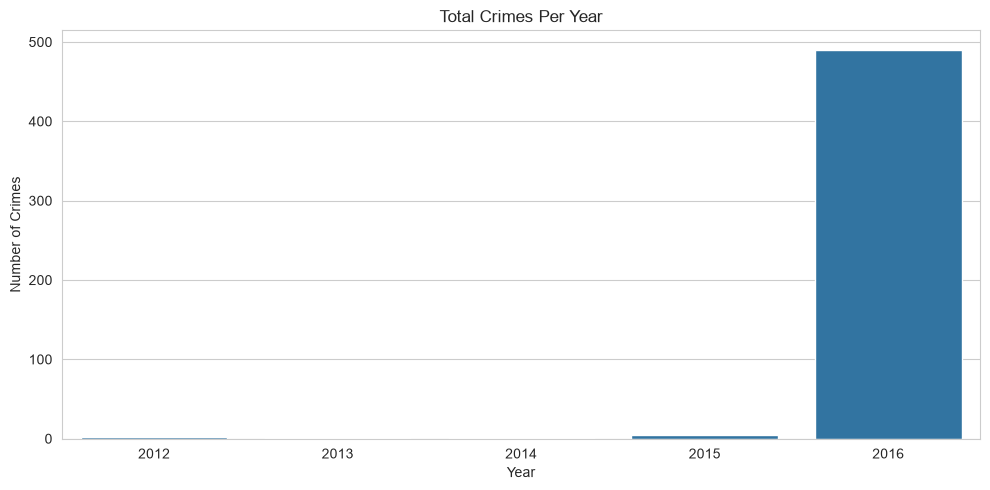

In [54]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=yearly_df,
    x='year',
    y='total_crimes'
)

plt.title("Total Crimes Per Year")
plt.xlabel("Year")
plt.ylabel("Number of Crimes")
plt.tight_layout()
plt.show()

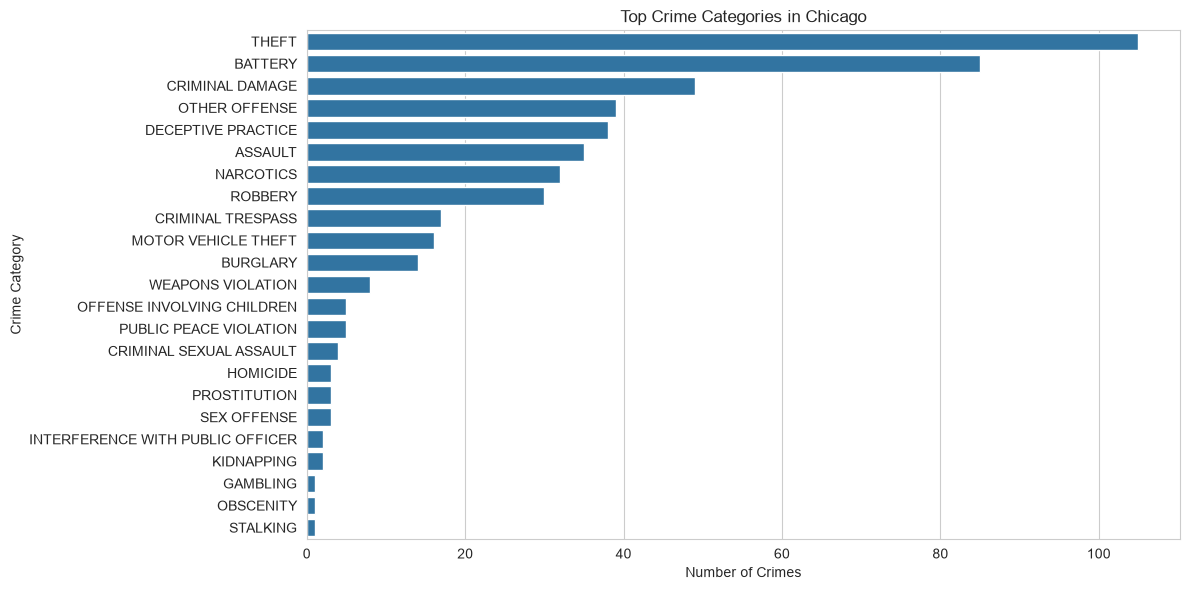

In [55]:
plt.figure(figsize=(12, 6))

top_crimes = category_df.sort_values(
    by='crime_count',
    ascending=False
)

sns.barplot(
    data=top_crimes,
    x='crime_count',
    y='primary_type'
)

plt.title("Top Crime Categories in Chicago")
plt.xlabel("Number of Crimes")
plt.ylabel("Crime Category")
plt.tight_layout()
plt.show()

In [56]:
# Arrest distribution

arrest_df = pd.read_sql_query("""
SELECT
    CASE
        WHEN arrest = 1 THEN 'Arrest'
        ELSE 'No Arrest'
    END AS arrest_status,
    COUNT(*) AS total
FROM crime
GROUP BY arrest
""", conn)

display(arrest_df)

,arrest_status,total
0,No Arrest,374
1,Arrest,124


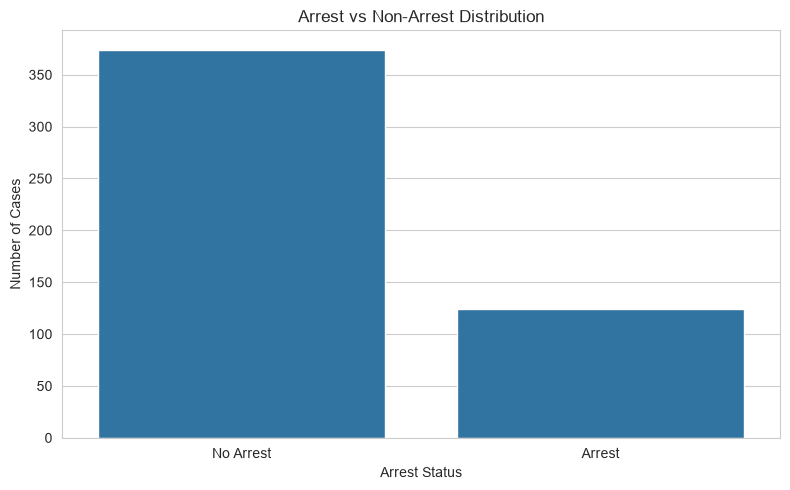

In [57]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=arrest_df,
    x='arrest_status',
    y='total'
)

plt.title("Arrest vs Non-Arrest Distribution")
plt.xlabel("Arrest Status")
plt.ylabel("Number of Cases")

plt.tight_layout()
plt.show()

In [58]:
# Crime distribution by day of week

query = """
SELECT
    DayOfWeek,
    COUNT(*) AS total_crimes
FROM crime
GROUP BY DayOfWeek
ORDER BY total_crimes DESC;
"""

weekday_df = pd.read_sql_query(query, conn)

display(weekday_df)

,DayOfWeek,total_crimes
0,Wednesday,303
1,Tuesday,156
2,Monday,12
3,Friday,11
4,Sunday,6
5,Thursday,5
6,Saturday,5


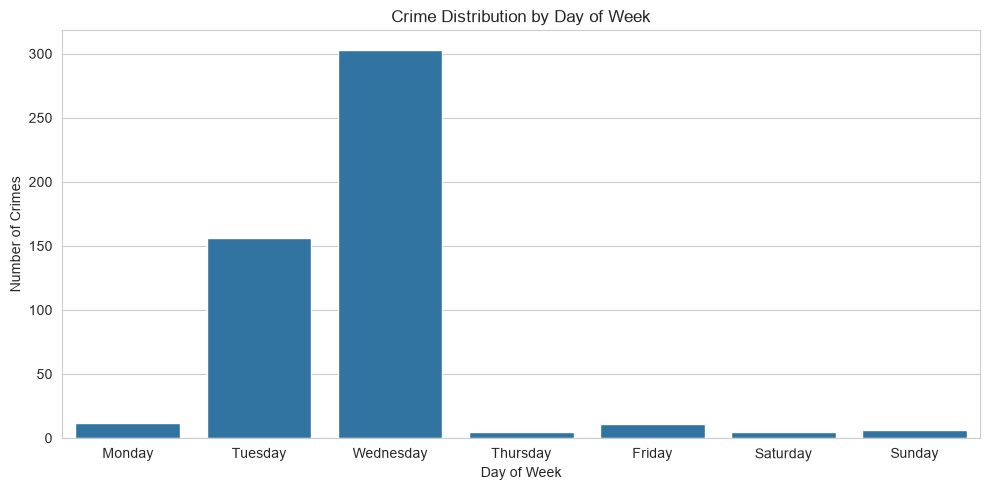

In [59]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=weekday_df,
    x='DayOfWeek',
    y='total_crimes',
    order=[
        'Monday', 'Tuesday', 'Wednesday',
        'Thursday', 'Friday', 'Saturday', 'Sunday'
    ]
)

plt.title("Crime Distribution by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Crimes")

plt.tight_layout()
plt.show()

In [60]:
# Crime distribution by community area

query = """
SELECT
    community_code,
    COUNT(*) AS total_crimes
FROM crime
WHERE community_code IS NOT NULL
GROUP BY community_code
ORDER BY total_crimes DESC
LIMIT 10;
"""

community_df = pd.read_sql_query(query, conn)

display(community_df)

,community_code,total_crimes
0,25,34
1,23,20
2,8,20
3,68,16
4,43,16
5,30,16
6,32,15
7,71,14
8,49,14
9,6,14


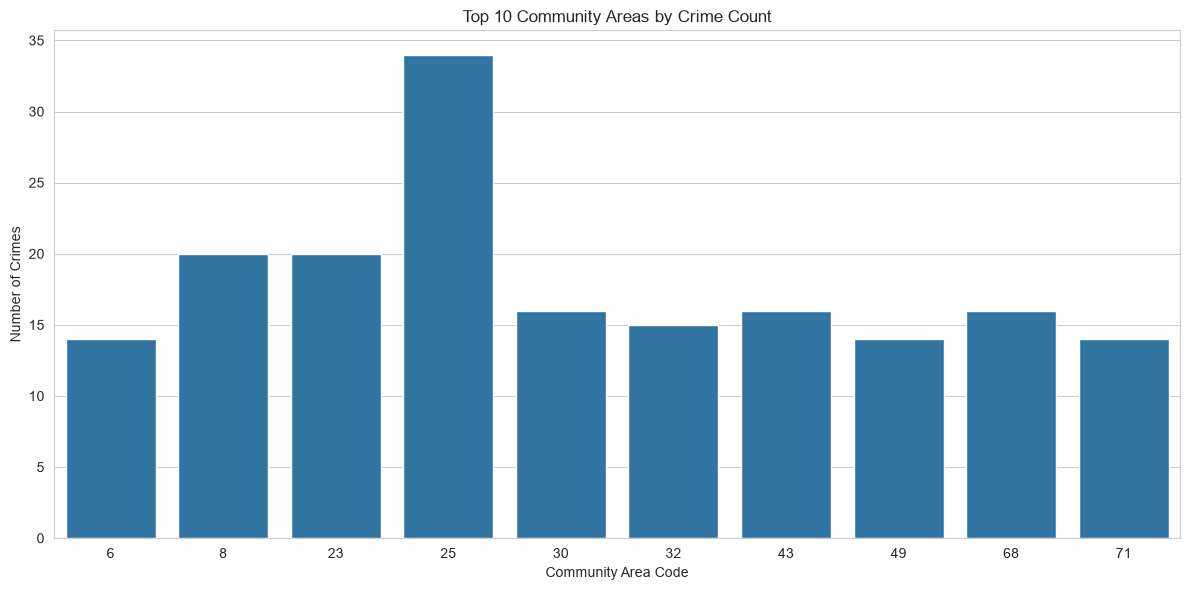

In [61]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=community_df,
    x='community_code',
    y='total_crimes'
)

plt.title("Top 10 Community Areas by Crime Count")
plt.xlabel("Community Area Code")
plt.ylabel("Number of Crimes")

plt.tight_layout()
plt.show()

In [62]:
query = """
SELECT
    CASE
        WHEN domestic = 1 THEN 'Domestic'
        ELSE 'Non-Domestic'
    END AS crime_type,
    COUNT(*) AS total_crimes
FROM crime
GROUP BY domestic;
"""

domestic_df = pd.read_sql_query(query, conn)

display(domestic_df)

,crime_type,total_crimes
0,Non-Domestic,430
1,Domestic,68


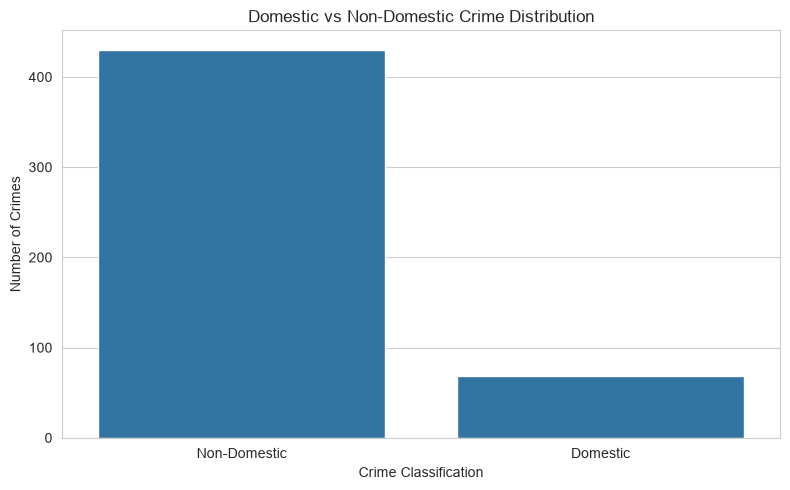

In [63]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=domestic_df,
    x='crime_type',
    y='total_crimes'
)

plt.title("Domestic vs Non-Domestic Crime Distribution")
plt.xlabel("Crime Classification")
plt.ylabel("Number of Crimes")

plt.tight_layout()
plt.show()

In [64]:
query = """
SELECT
    location_desc,
    COUNT(*) AS total_crimes
FROM crime
WHERE location_desc IS NOT NULL
GROUP BY location_desc
ORDER BY total_crimes DESC
LIMIT 10;
"""

location_df = pd.read_sql_query(query, conn)

display(location_df)

,location_desc,total_crimes
0,STREET,105
1,RESIDENCE,75
2,APARTMENT,54
3,SIDEWALK,50
4,OTHER,28
5,"SCHOOL, PUBLIC, BUILDING",19
6,SMALL RETAIL STORE,15
7,PARKING LOT/GARAGE(NON.RESID.),14
8,RESIDENTIAL YARD (FRONT/BACK),13
9,RESIDENCE-GARAGE,12


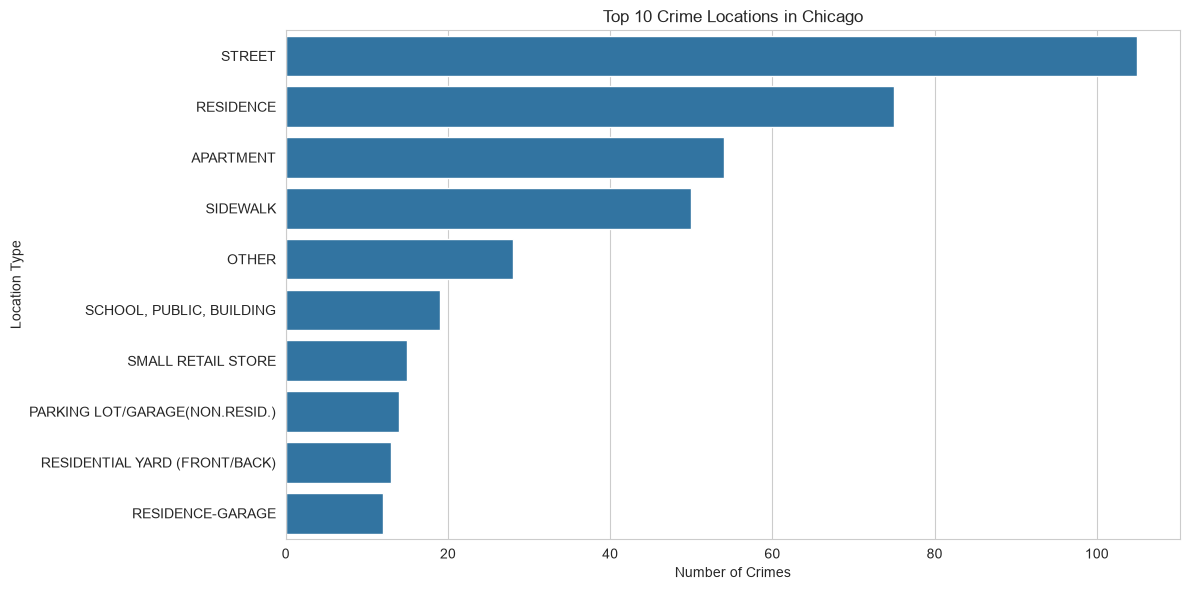

In [65]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=location_df,
    x='total_crimes',
    y='location_desc'
)

plt.title("Top 10 Crime Locations in Chicago")
plt.xlabel("Number of Crimes")
plt.ylabel("Location Type")

plt.tight_layout()
plt.show()

In [66]:
# Crime distribution using geographical coordinates

query = """
SELECT
    latitude,
    longitude,
    COUNT(*) AS total_crimes
FROM crime
WHERE latitude IS NOT NULL
AND longitude IS NOT NULL
GROUP BY latitude, longitude
ORDER BY total_crimes DESC
LIMIT 15;
"""

geo_df = pd.read_sql_query(query, conn)

display(geo_df)

,latitude,longitude,total_crimes
0,41.736277,-87.625105,2
1,41.754593,-87.741529,2
2,41.764155,-87.649243,2
3,41.800483,-87.587415,2
4,41.877822,-87.655181,2
5,41.883754,-87.626232,2
6,41.906507,-87.767022,2
7,41.911591,-87.735312,2
8,41.956081,-87.727687,2
9,41.984278,-87.671012,2


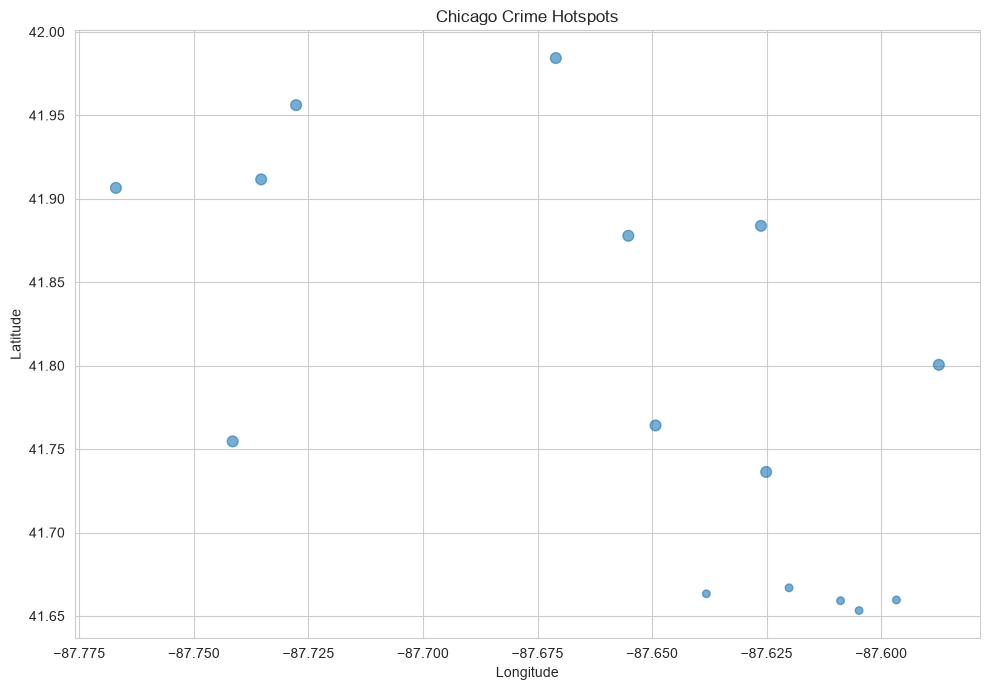

In [67]:
plt.figure(figsize=(10, 7))

plt.scatter(
    geo_df['longitude'],
    geo_df['latitude'],
    s=geo_df['total_crimes'] * 30,
    alpha=0.6
)

plt.title("Chicago Crime Hotspots")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.tight_layout()
plt.show()

In [68]:
# Prepare geographical data

geo_all_df = pd.read_sql_query("""
SELECT latitude, longitude
FROM crime
WHERE latitude IS NOT NULL
AND longitude IS NOT NULL
""", conn)

print("Total geographical records:", len(geo_all_df))
print(geo_all_df.describe())

Total geographical records: 469
         latitude   longitude
count  469.000000  469.000000
mean    41.842657  -87.671066
std      0.083555    0.059561
min     41.653250  -87.839659
25%     41.772678  -87.714673
50%     41.852793  -87.660998
75%     41.899610  -87.626232
max     42.019399  -87.535758


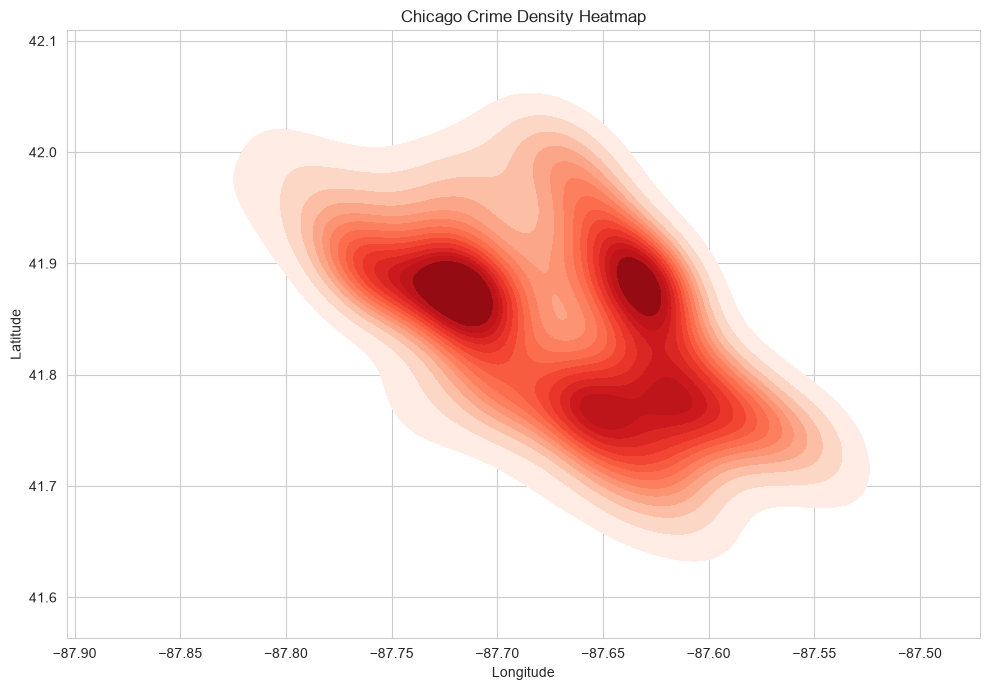

In [69]:
plt.figure(figsize=(10, 7))

sns.kdeplot(
    data=geo_all_df,
    x='longitude',
    y='latitude',
    fill=True,
    cmap='Reds',
    levels=15,
    thresh=0.05
)

plt.title("Chicago Crime Density Heatmap")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.tight_layout()
plt.show()

In [70]:
# Crime distribution by police district

query = """
SELECT
    district_code,
    COUNT(*) AS total_crimes,
    SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END) AS arrests
FROM crime
GROUP BY district_code
ORDER BY total_crimes DESC;
"""

district_df = pd.read_sql_query(query, conn)

display(district_df)

,district_code,total_crimes,arrests
0,11,40,17
1,8,30,6
2,7,30,5
3,6,30,11
4,3,28,12
5,2,27,6
6,1,27,4
7,25,26,10
8,10,26,8
9,4,26,4


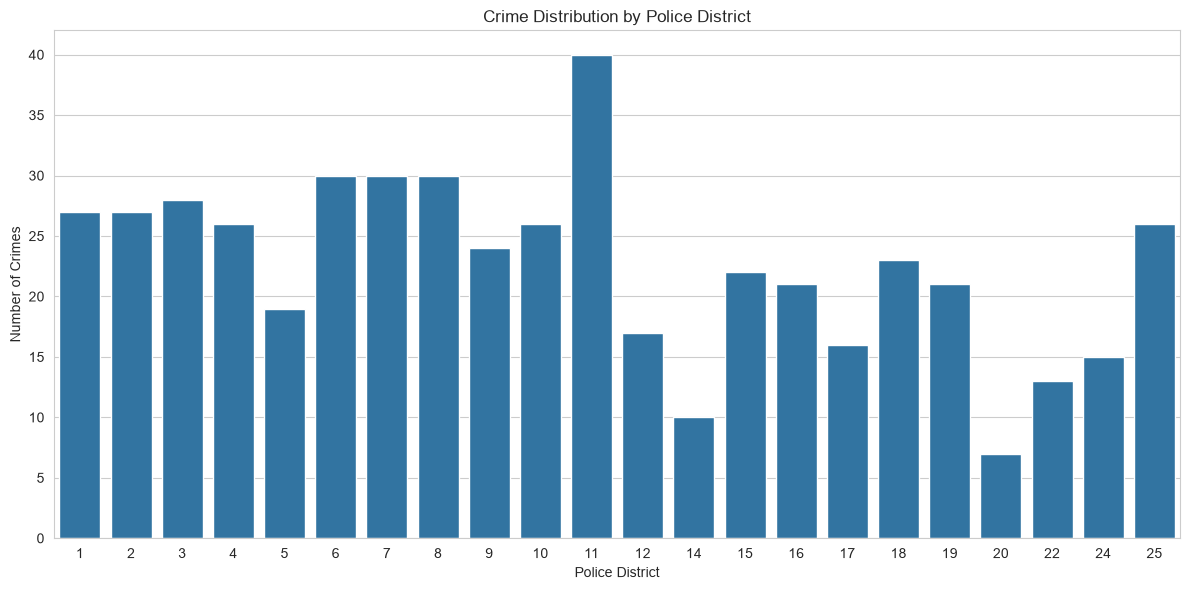

In [71]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=district_df,
    x='district_code',
    y='total_crimes'
)

plt.title("Crime Distribution by Police District")
plt.xlabel("Police District")
plt.ylabel("Number of Crimes")

plt.tight_layout()
plt.show()

In [72]:
# Calculate arrest rate by district

district_df['arrest_rate'] = (
    district_df['arrests'] /
    district_df['total_crimes']
) * 100

district_df = district_df.sort_values(
    by='arrest_rate',
    ascending=False
)

display(district_df)

,district_code,total_crimes,arrests,arrest_rate
4,3,28,12,42.857143
21,20,7,3,42.857143
0,11,40,17,42.500000
7,25,26,10,38.461538
3,6,30,11,36.666667
12,15,22,8,36.363636
8,10,26,8,30.769231
18,24,15,4,26.666667
13,19,21,5,23.809524
16,12,17,4,23.529412


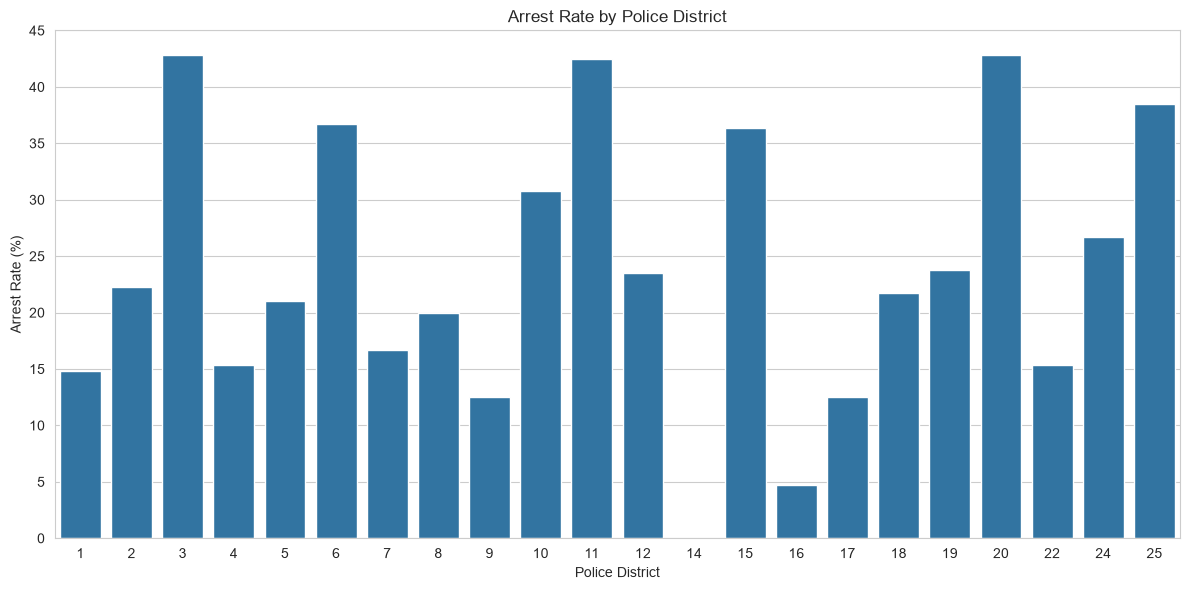

In [73]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=district_df,
    x='district_code',
    y='arrest_rate'
)

plt.title("Arrest Rate by Police District")
plt.xlabel("Police District")
plt.ylabel("Arrest Rate (%)")

plt.tight_layout()
plt.show()

In [74]:
# Monthly crime distribution

monthly_crimes = pd.read_sql_query("""
SELECT
    Month,
    COUNT(*) AS total_crimes
FROM crime
GROUP BY Month
ORDER BY Month;
""", conn)

display(monthly_crimes)

,Month,total_crimes
0,1,10
1,2,5
2,3,12
3,4,22
4,5,447
5,11,2


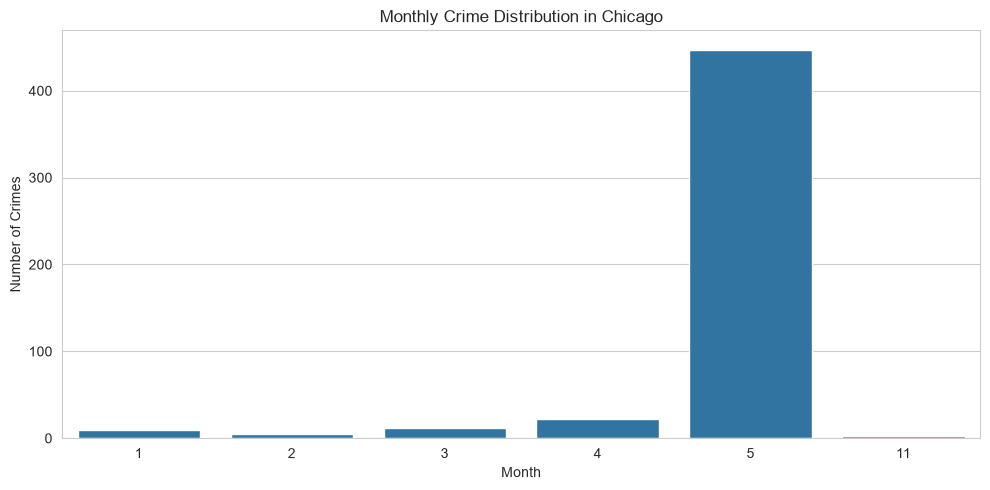

In [75]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=monthly_crimes,
    x='Month',
    y='total_crimes'
)

plt.title("Monthly Crime Distribution in Chicago")
plt.xlabel("Month")
plt.ylabel("Number of Crimes")

plt.tight_layout()
plt.show()

In [76]:
year_month_crimes = pd.read_sql_query("""
SELECT
    year,
    Month,
    COUNT(*) AS total_crimes
FROM crime
GROUP BY year, Month
ORDER BY year, Month;
""", conn)

display(year_month_crimes)

,year,Month,total_crimes
0,2012,1,2
1,2013,5,1
2,2014,11,1
3,2015,1,2
4,2015,5,1
5,2015,11,1
6,2016,1,6
7,2016,2,5
8,2016,3,12
9,2016,4,22


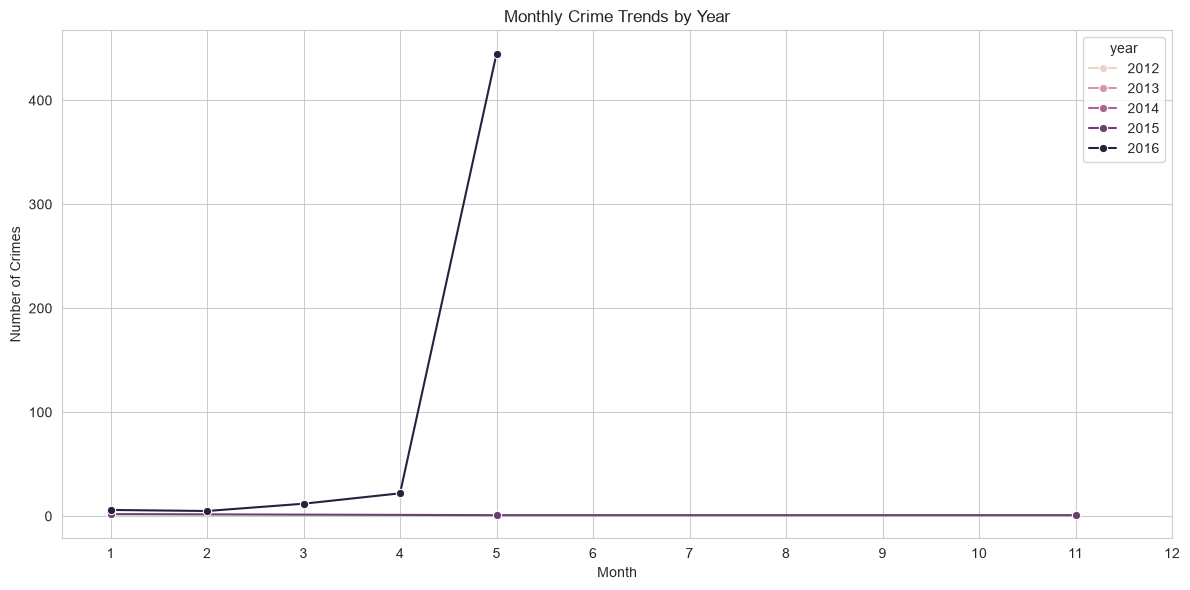

In [77]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=year_month_crimes,
    x='Month',
    y='total_crimes',
    hue='year',
    marker='o'
)

plt.title("Monthly Crime Trends by Year")
plt.xlabel("Month")
plt.ylabel("Number of Crimes")
plt.xticks(range(1, 13))
plt.grid(True)

plt.tight_layout()
plt.show()

In [78]:
crime_pivot = year_month_crimes.pivot(
    index='year',
    columns='Month',
    values='total_crimes'
).fillna(0)

display(crime_pivot)

Month,1,2,3,4,5,11
year,,,,,,
2012,2.0,0.0,0.0,0.0,0.0,0.0
2013,0.0,0.0,0.0,0.0,1.0,0.0
2014,0.0,0.0,0.0,0.0,0.0,1.0
2015,2.0,0.0,0.0,0.0,1.0,1.0
2016,6.0,5.0,12.0,22.0,445.0,0.0


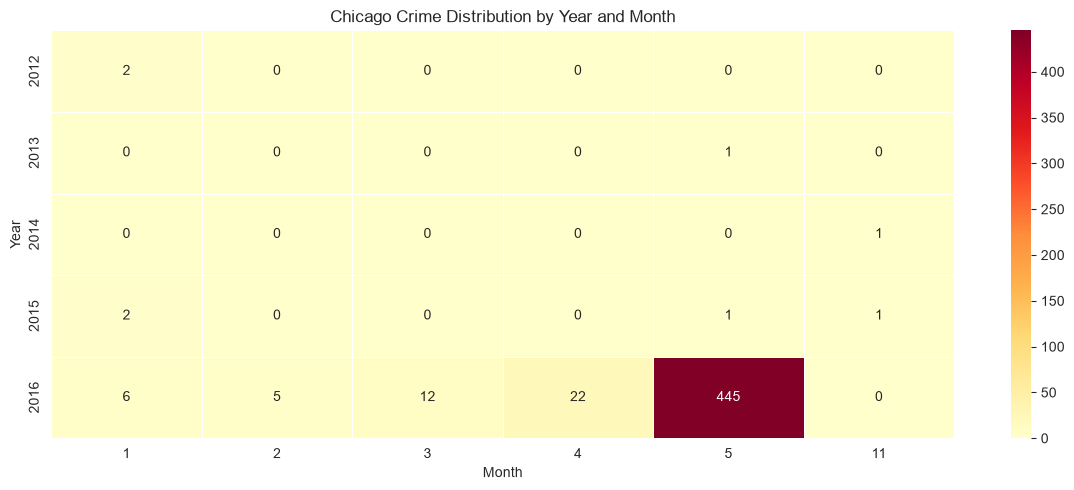

In [79]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    crime_pivot,
    annot=True,
    fmt='.0f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title("Chicago Crime Distribution by Year and Month")
plt.xlabel("Month")
plt.ylabel("Year")

plt.tight_layout()
plt.show()

In [80]:
arrest_analysis = pd.read_sql_query("""
SELECT
    primary_type,
    COUNT(*) AS total_cases,
    SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END) AS arrests,
    ROUND(
        100.0 * SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS arrest_rate
FROM crime
GROUP BY primary_type
ORDER BY total_cases DESC;
""", conn)

display(arrest_analysis)

,primary_type,total_cases,arrests,arrest_rate
0,THEFT,105,10,9.52
1,BATTERY,85,20,23.53
2,CRIMINAL DAMAGE,49,2,4.08
3,OTHER OFFENSE,39,8,20.51
4,DECEPTIVE PRACTICE,38,5,13.16
5,ASSAULT,35,10,28.57
6,NARCOTICS,32,32,100.00
7,ROBBERY,30,6,20.00
8,CRIMINAL TRESPASS,17,15,88.24
9,MOTOR VEHICLE THEFT,16,0,0.00


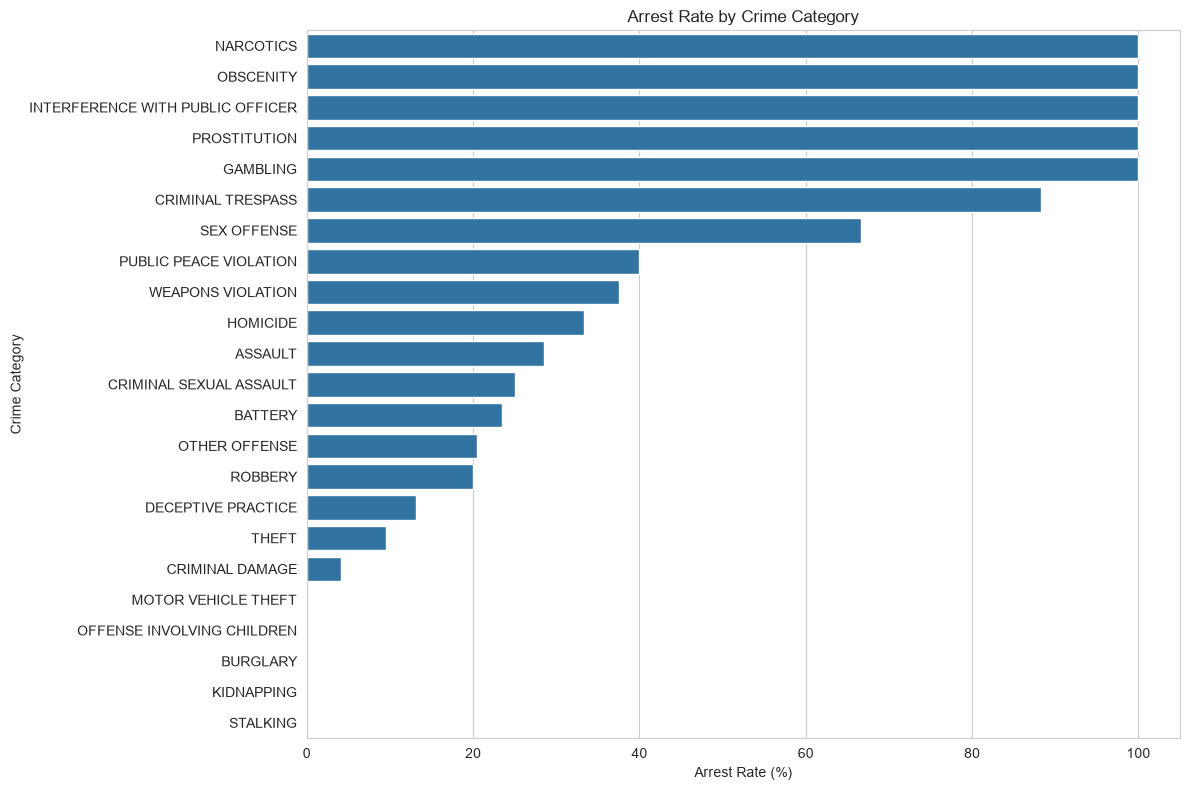

In [81]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=arrest_analysis.sort_values(
        'arrest_rate', ascending=False
    ),
    x='arrest_rate',
    y='primary_type'
)

plt.title("Arrest Rate by Crime Category")
plt.xlabel("Arrest Rate (%)")
plt.ylabel("Crime Category")

plt.tight_layout()
plt.show()

In [82]:
domestic_arrest = pd.read_sql_query("""
SELECT
    CASE
        WHEN domestic = 1 THEN 'Domestic'
        ELSE 'Non-Domestic'
    END AS crime_type,
    COUNT(*) AS total_cases,
    SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END) AS arrests,
    ROUND(
        100.0 * SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS arrest_rate
FROM crime
GROUP BY domestic
ORDER BY total_cases DESC;
""", conn)

display(domestic_arrest)

,crime_type,total_cases,arrests,arrest_rate
0,Non-Domestic,430,106,24.65
1,Domestic,68,18,26.47


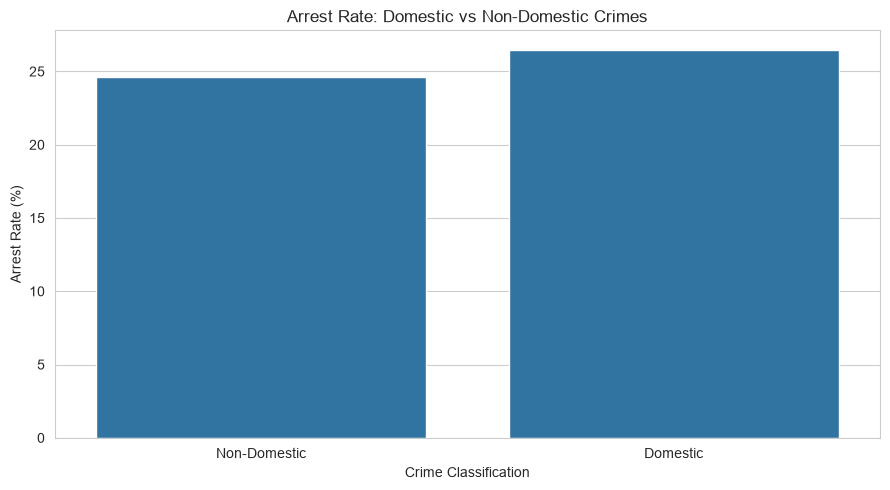

In [83]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=domestic_arrest,
    x='crime_type',
    y='arrest_rate'
)

plt.title("Arrest Rate: Domestic vs Non-Domestic Crimes")
plt.xlabel("Crime Classification")
plt.ylabel("Arrest Rate (%)")

plt.tight_layout()
plt.show()

In [84]:
district_analysis = pd.read_sql_query("""
SELECT
    district_code,
    COUNT(*) AS total_crimes,
    SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END) AS arrests,
    ROUND(
        100.0 * SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS arrest_rate
FROM crime
GROUP BY district_code
ORDER BY total_crimes DESC;
""", conn)

display(district_analysis)

,district_code,total_crimes,arrests,arrest_rate
0,11,40,17,42.50
1,8,30,6,20.00
2,7,30,5,16.67
3,6,30,11,36.67
4,3,28,12,42.86
5,2,27,6,22.22
6,1,27,4,14.81
7,25,26,10,38.46
8,10,26,8,30.77
9,4,26,4,15.38


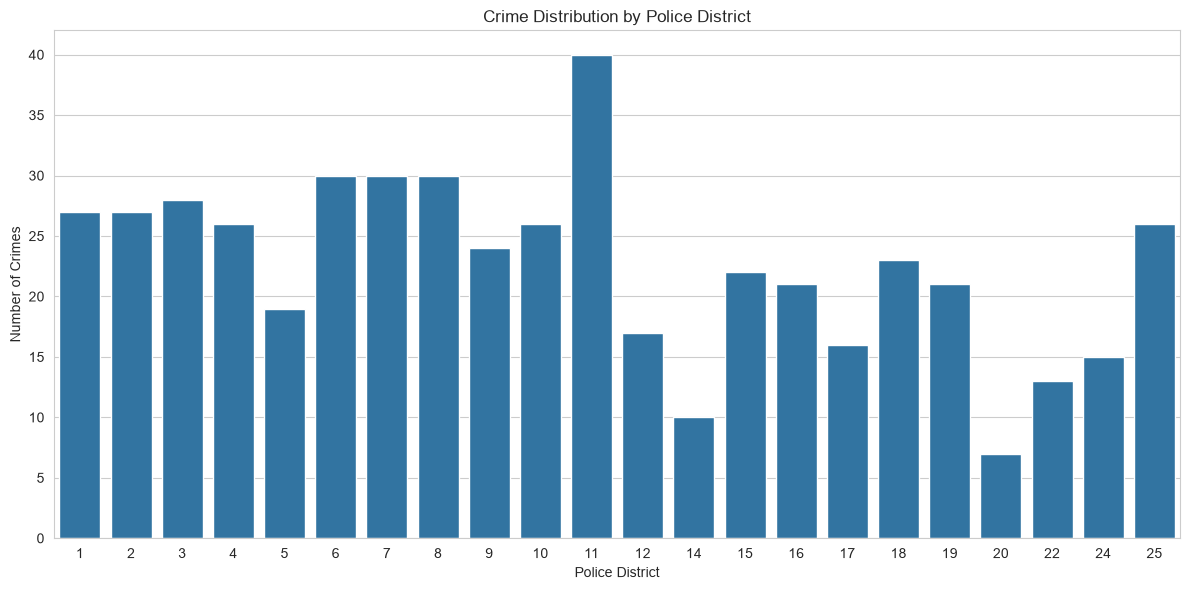

In [85]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=district_analysis.sort_values(
        'total_crimes', ascending=False
    ),
    x='district_code',
    y='total_crimes'
)

plt.title("Crime Distribution by Police District")
plt.xlabel("Police District")
plt.ylabel("Number of Crimes")

plt.tight_layout()
plt.show()

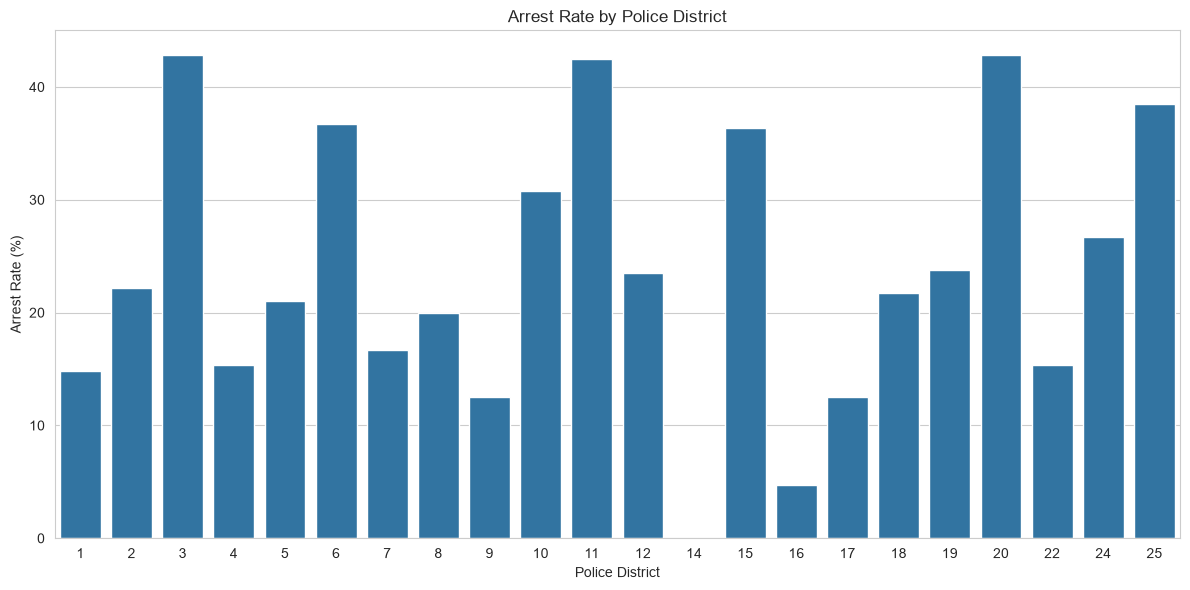

In [86]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=district_analysis.sort_values(
        'arrest_rate', ascending=False
    ),
    x='district_code',
    y='arrest_rate'
)

plt.title("Arrest Rate by Police District")
plt.xlabel("Police District")
plt.ylabel("Arrest Rate (%)")

plt.tight_layout()
plt.show()

In [87]:
# Crime hotspot analysis

hotspots = pd.read_sql_query("""
SELECT
    ROUND(latitude, 3) AS latitude,
    ROUND(longitude, 3) AS longitude,
    COUNT(*) AS total_crimes
FROM crime
WHERE latitude IS NOT NULL
  AND longitude IS NOT NULL
GROUP BY
    ROUND(latitude, 3),
    ROUND(longitude, 3)
ORDER BY total_crimes DESC;
""", conn)

print("Top 15 geographical crime hotspots:")
display(hotspots.head(15))

Top 15 geographical crime hotspots:


,latitude,longitude,total_crimes
0,41.884,-87.626,3
1,41.707,-87.624,2
2,41.736,-87.625,2
3,41.737,-87.546,2
4,41.742,-87.578,2
5,41.755,-87.742,2
6,41.764,-87.649,2
7,41.800,-87.587,2
8,41.878,-87.655,2
9,41.890,-87.638,2


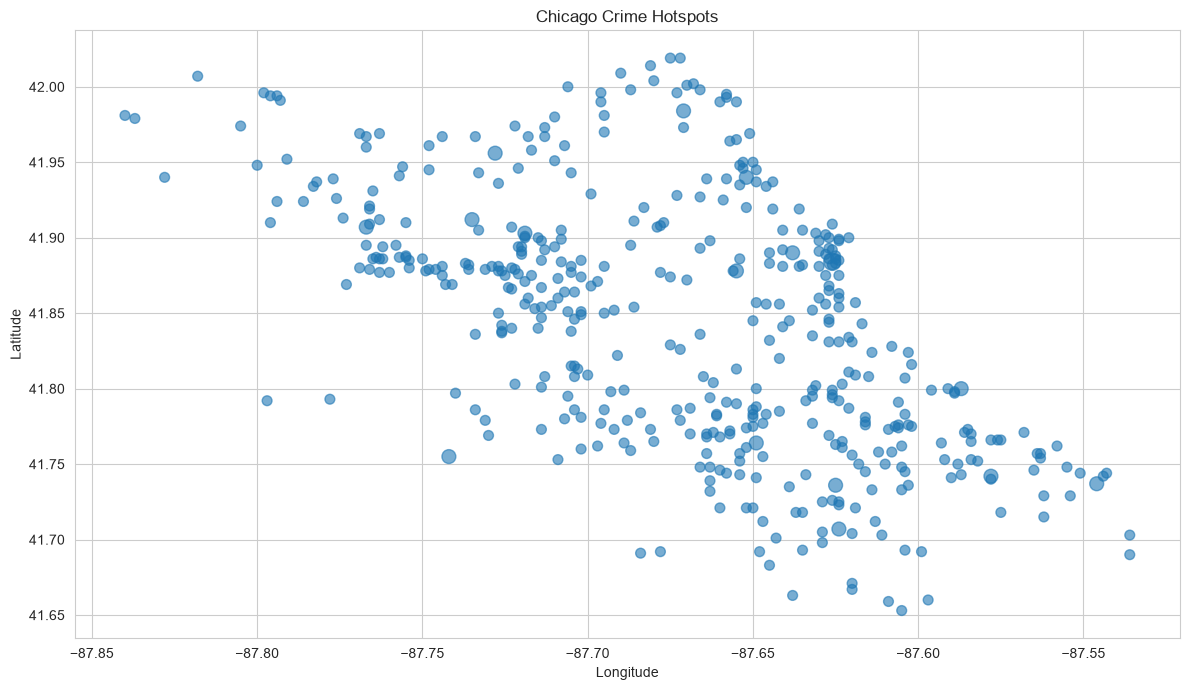

In [88]:
plt.figure(figsize=(12, 7))

plt.scatter(
    hotspots['longitude'],
    hotspots['latitude'],
    s=hotspots['total_crimes'] * 50,
    alpha=0.6
)

plt.title("Chicago Crime Hotspots")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True)

plt.tight_layout()
plt.show()

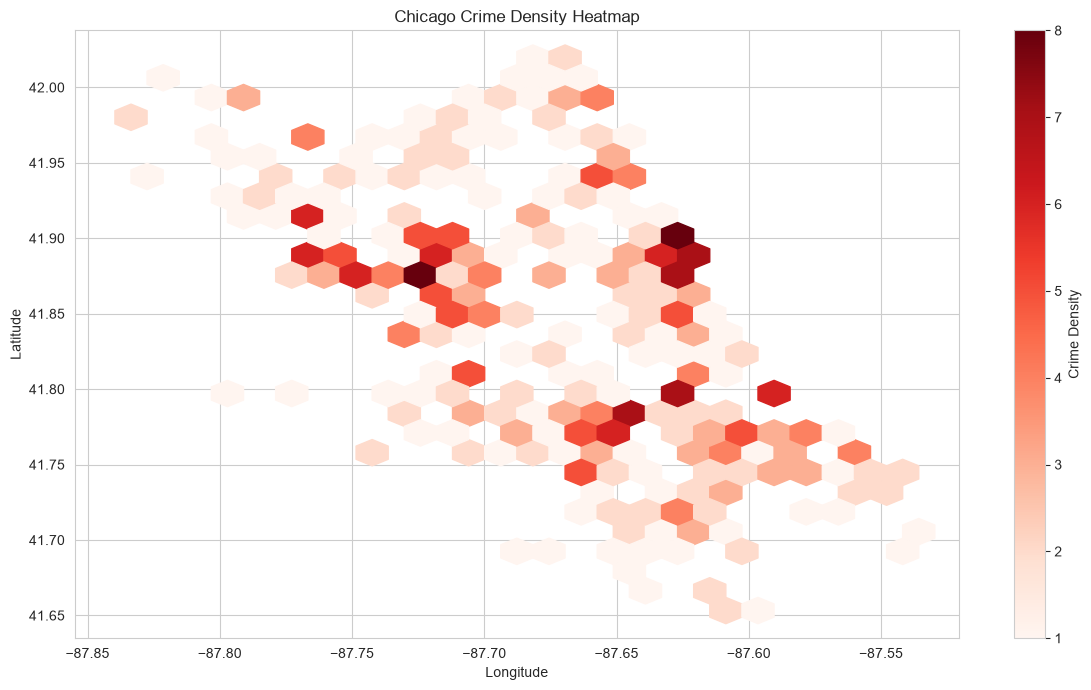

In [89]:
plt.figure(figsize=(12, 7))

plt.hexbin(
    df['longitude'],
    df['latitude'],
    gridsize=25,
    cmap='Reds',
    mincnt=1
)

plt.colorbar(label='Crime Density')

plt.title("Chicago Crime Density Heatmap")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.tight_layout()
plt.show()

In [90]:
geo_summary = df[
    ['latitude', 'longitude']
].dropna().describe()

print("Geographical Data Summary:")
display(geo_summary)

print("Total geographical records:",
      df[['latitude', 'longitude']].dropna().shape[0])

Geographical Data Summary:


,latitude,longitude
count,469.000000,469.000000
mean,41.842657,-87.671066
std,0.083555,0.059561
min,41.653250,-87.839659
25%,41.772678,-87.714673
50%,41.852793,-87.660998
75%,41.899610,-87.626232
max,42.019399,-87.535758


Total geographical records: 469


In [91]:
community_analysis = pd.read_sql_query("""
SELECT
    community_code,
    COUNT(*) AS total_crimes,
    SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END) AS arrests,
    ROUND(
        100.0 * SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS arrest_rate
FROM crime
WHERE community_code IS NOT NULL
GROUP BY community_code
ORDER BY total_crimes DESC;
""", conn)

print("Community Area Crime Analysis:")
display(community_analysis)

Community Area Crime Analysis:


,community_code,total_crimes,arrests,arrest_rate
0,25,34,13,38.24
1,23,20,6,30.00
2,8,20,5,25.00
3,68,16,4,25.00
4,43,16,5,31.25
5,30,16,4,25.00
6,32,15,3,20.00
7,71,14,4,28.57
8,49,14,5,35.71
9,6,14,2,14.29


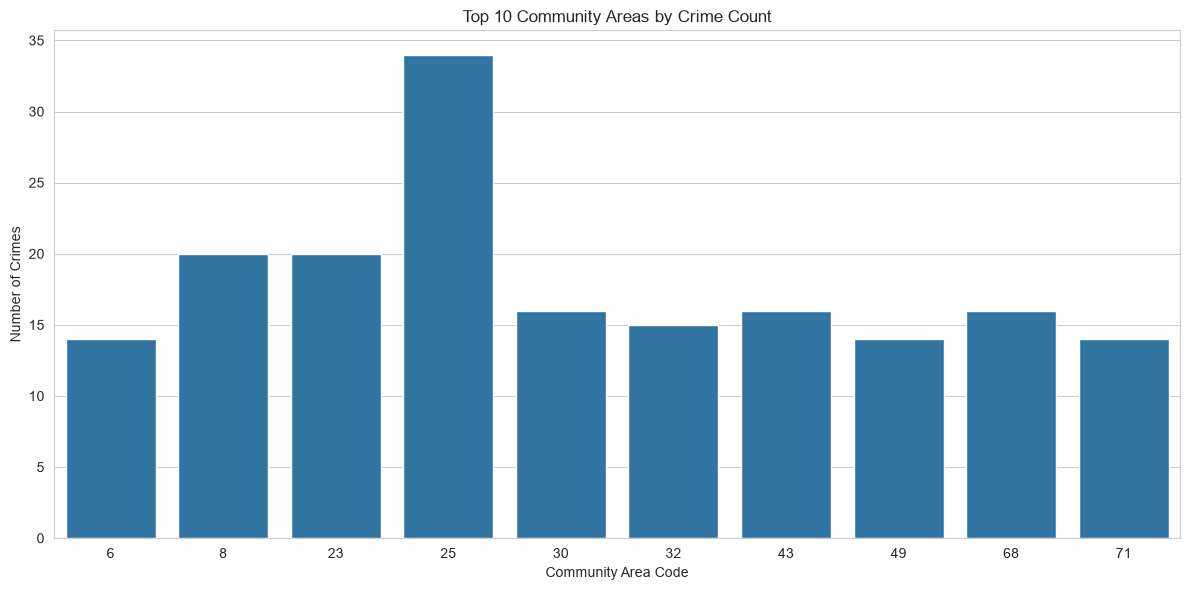

In [92]:
top_communities = community_analysis.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_communities,
    x='community_code',
    y='total_crimes'
)

plt.title("Top 10 Community Areas by Crime Count")
plt.xlabel("Community Area Code")
plt.ylabel("Number of Crimes")

plt.tight_layout()
plt.show()

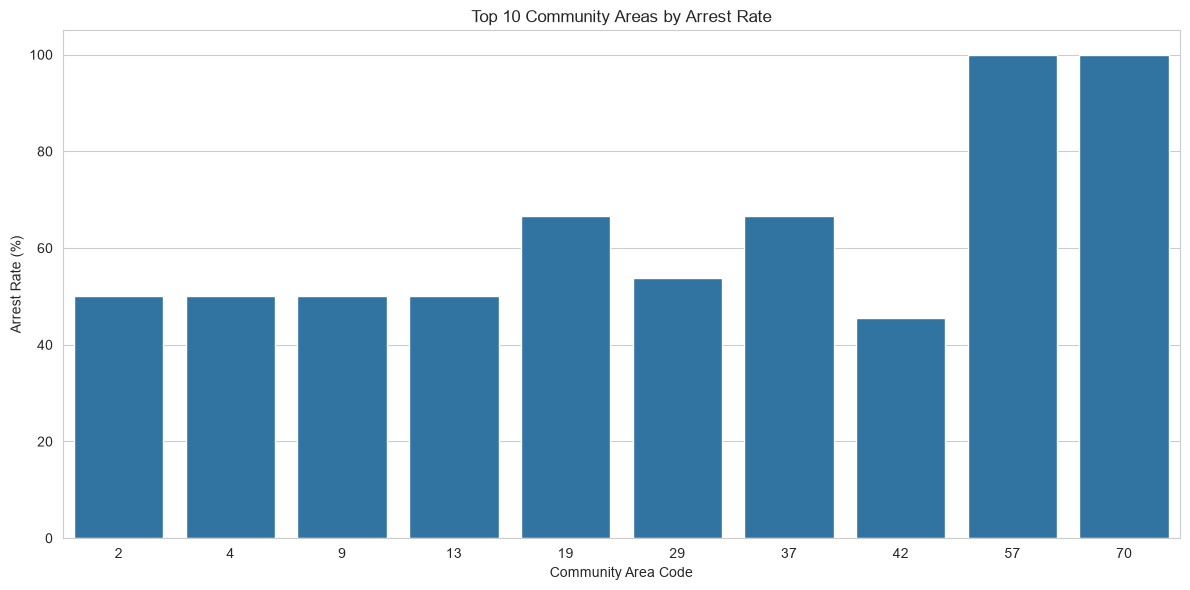

In [93]:
top_arrest_communities = community_analysis.sort_values(
    'arrest_rate', ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_arrest_communities,
    x='community_code',
    y='arrest_rate'
)

plt.title("Top 10 Community Areas by Arrest Rate")
plt.xlabel("Community Area Code")
plt.ylabel("Arrest Rate (%)")

plt.tight_layout()
plt.show()

In [94]:
print("Total community areas:", len(community_analysis))

print("\nHighest crime community area:")
display(community_analysis.head(1))

print("\nHighest arrest-rate community areas:")
display(top_arrest_communities)

Total community areas: 70

Highest crime community area:


,community_code,total_crimes,arrests,arrest_rate
0,25,34,13,38.24



Highest arrest-rate community areas:


,community_code,total_crimes,arrests,arrest_rate
65,70,1,1,100.00
66,57,1,1,100.00
52,37,3,2,66.67
20,19,9,6,66.67
12,29,13,7,53.85
61,13,2,1,50.00
63,9,2,1,50.00
64,4,2,1,50.00
34,2,6,3,50.00
16,42,11,5,45.45


In [95]:
yearly_summary = pd.read_sql_query("""
SELECT
    year,
    COUNT(*) AS total_crimes,
    SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END) AS arrests,
    SUM(CASE WHEN domestic = 1 THEN 1 ELSE 0 END) AS domestic_cases
FROM crime
GROUP BY year
ORDER BY year;
""", conn)

display(yearly_summary)

,year,total_crimes,arrests,domestic_cases
0,2012,2,2,0
1,2013,1,1,0
2,2014,1,0,0
3,2015,4,2,1
4,2016,490,119,67


In [96]:
top_crimes = pd.read_sql_query("""
SELECT
    primary_type,
    COUNT(*) AS total_cases,
    ROUND(
        100.0 * COUNT(*) / (SELECT COUNT(*) FROM crime), 2
    ) AS percentage
FROM crime
GROUP BY primary_type
ORDER BY total_cases DESC
LIMIT 10;
""", conn)

display(top_crimes)

,primary_type,total_cases,percentage
0,THEFT,105,21.08
1,BATTERY,85,17.07
2,CRIMINAL DAMAGE,49,9.84
3,OTHER OFFENSE,39,7.83
4,DECEPTIVE PRACTICE,38,7.63
5,ASSAULT,35,7.03
6,NARCOTICS,32,6.43
7,ROBBERY,30,6.02
8,CRIMINAL TRESPASS,17,3.41
9,MOTOR VEHICLE THEFT,16,3.21


In [97]:
arrest_summary = pd.read_sql_query("""
SELECT
    CASE
        WHEN arrest = 1 THEN 'Arrest'
        ELSE 'No Arrest'
    END AS arrest_status,
    COUNT(*) AS total_cases
FROM crime
GROUP BY arrest
ORDER BY total_cases DESC;
""", conn)

display(arrest_summary)

,arrest_status,total_cases
0,No Arrest,374
1,Arrest,124


In [98]:
domestic_summary = pd.read_sql_query("""
SELECT
    CASE
        WHEN domestic = 1 THEN 'Domestic'
        ELSE 'Non-Domestic'
    END AS crime_type,
    COUNT(*) AS total_cases,
    SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END) AS arrests
FROM crime
GROUP BY domestic;
""", conn)

display(domestic_summary)

,crime_type,total_cases,arrests
0,Non-Domestic,430,106
1,Domestic,68,18


In [99]:
top_districts = pd.read_sql_query("""
SELECT
    district_code,
    COUNT(*) AS total_crimes,
    SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END) AS arrests
FROM crime
GROUP BY district_code
ORDER BY total_crimes DESC
LIMIT 10;
""", conn)

display(top_districts)

,district_code,total_crimes,arrests
0,11,40,17
1,8,30,6
2,7,30,5
3,6,30,11
4,3,28,12
5,2,27,6
6,1,27,4
7,25,26,10
8,10,26,8
9,4,26,4


In [100]:
location_summary = pd.read_sql_query("""
SELECT
    location_desc,
    COUNT(*) AS total_crimes
FROM crime
GROUP BY location_desc
ORDER BY total_crimes DESC
LIMIT 10;
""", conn)

display(location_summary)

,location_desc,total_crimes
0,STREET,105
1,RESIDENCE,75
2,APARTMENT,54
3,SIDEWALK,50
4,OTHER,28
5,"SCHOOL, PUBLIC, BUILDING",19
6,SMALL RETAIL STORE,15
7,PARKING LOT/GARAGE(NON.RESID.),14
8,RESIDENTIAL YARD (FRONT/BACK),13
9,RESIDENCE-GARAGE,12


In [101]:
weekday_summary = pd.read_sql_query("""
SELECT
    DayOfWeek,
    COUNT(*) AS total_crimes
FROM crime
GROUP BY DayOfWeek
ORDER BY total_crimes DESC;
""", conn)

display(weekday_summary)

,DayOfWeek,total_crimes
0,Wednesday,303
1,Tuesday,156
2,Monday,12
3,Friday,11
4,Sunday,6
5,Thursday,5
6,Saturday,5


In [102]:
final_summary = pd.read_sql_query("""
SELECT
    COUNT(*) AS total_records,
    COUNT(DISTINCT case_number) AS unique_cases,
    COUNT(DISTINCT primary_type) AS crime_categories,
    COUNT(DISTINCT district_code) AS police_districts,
    COUNT(DISTINCT community_code) AS community_areas,
    SUM(CASE WHEN arrest = 1 THEN 1 ELSE 0 END) AS total_arrests,
    SUM(CASE WHEN domestic = 1 THEN 1 ELSE 0 END) AS domestic_crimes
FROM crime;
""", conn)

display(final_summary)

,total_records,unique_cases,crime_categories,police_districts,community_areas,total_arrests,domestic_crimes
0,498,498,23,22,70,124,68


In [103]:
import os

reports_dir = os.path.abspath(
    os.path.join(os.getcwd(), "..", "reports")
)

analysis_dir = os.path.join(
    reports_dir, "analysis_results"
)

os.makedirs(analysis_dir, exist_ok=True)

print("Reports directory:", reports_dir)
print("Analysis directory:", analysis_dir)

Reports directory: C:\Users\prashant.k.saraswat\Downloads\Chicago-Crime-Capstone\reports
Analysis directory: C:\Users\prashant.k.saraswat\Downloads\Chicago-Crime-Capstone\reports\analysis_results


In [104]:
cleaned_csv_path = os.path.join(
    reports_dir,
    "chicago_crime_cleaned.csv"
)

df.to_csv(cleaned_csv_path, index=False)

print("Cleaned dataset exported successfully!")
print("Location:", cleaned_csv_path)
print("Records:", len(df))

Cleaned dataset exported successfully!
Location: C:\Users\prashant.k.saraswat\Downloads\Chicago-Crime-Capstone\reports\chicago_crime_cleaned.csv
Records: 498


In [105]:
analysis_tables = {
    "yearly_summary": yearly_summary,
    "top_crimes": top_crimes,
    "arrest_summary": arrest_summary,
    "domestic_summary": domestic_summary,
    "top_districts": top_districts,
    "location_summary": location_summary,
    "weekday_summary": weekday_summary,
    "community_analysis": community_analysis,
    "hotspots": hotspots,
    "district_analysis": district_analysis,
    "arrest_analysis": arrest_analysis,
    "domestic_arrest": domestic_arrest,
    "monthly_crimes": monthly_crimes,
    "year_month_crimes": year_month_crimes,
    "final_summary": final_summary
}

for name, table in analysis_tables.items():

    file_path = os.path.join(
        analysis_dir,
        name + ".csv"
    )

    table.to_csv(file_path, index=False)

print("All analysis results exported successfully!")
print("Total analysis files:", len(analysis_tables))

All analysis results exported successfully!
Total analysis files: 15


In [106]:
# Commit all database changes

conn.commit()

db_path = os.path.abspath(
    os.path.join("..", "reports", "chicago_crime.db")
)

print("Database exists:", os.path.exists(db_path))

if os.path.exists(db_path):
    print("Database size:",
          round(os.path.getsize(db_path) / 1024, 2),
          "KB")

# Verify the crime table

verification = pd.read_sql_query(
    "SELECT COUNT(*) AS total_records FROM crime",
    conn
)

display(verification)

print("SQLite database verified successfully!")

Database exists: True
Database size: 108.0 KB


,total_records
0,498


SQLite database verified successfully!


In [112]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Check whether time information is available
df['date'] = pd.to_datetime(df['date'], errors='coerce')

time_values = df['date'].dropna()

print("Hourly Crime Analysis")
print("-" * 40)

if not time_values.empty and (
    (time_values.dt.hour != 0).any()
    or (time_values.dt.minute != 0).any()
    or (time_values.dt.second != 0).any()
):

    df['Hour'] = df['date'].dt.hour

    hourly_crimes = (
        df.groupby('Hour')
        .size()
        .reindex(range(24), fill_value=0)
        .reset_index(name='crime_count')
    )

    display(hourly_crimes)

    plt.figure(figsize=(12, 6))

    sns.lineplot(
        data=hourly_crimes,
        x='Hour',
        y='crime_count',
        marker='o'
    )

    plt.title('Crime Frequency by Hour')
    plt.xlabel('Hour of Day')
    plt.ylabel('Number of Crimes')
    plt.xticks(range(24))
    plt.grid(True)
    plt.tight_layout()
    plt.show()

else:

    print("Hourly analysis cannot be performed.")
    print("The provided dataset does not contain actual time information.")
    print("Only calendar dates are available in the date column.")


Hourly Crime Analysis
----------------------------------------
Hourly analysis cannot be performed.
The provided dataset does not contain actual time information.
Only calendar dates are available in the date column.


Community Area Statistical Summary
----------------------------------------
Total Community Areas: 70
Mean Crime Count: 7.11
Median Crime Count: 6.0
Q1: 3.0
Q3: 9.0
IQR: 6.0
Lower Bound: -6.0
Upper Bound: 18.0

Extreme Crime Count Outliers:


,community_code,total_crimes
6,8,20
19,23,20
21,25,34


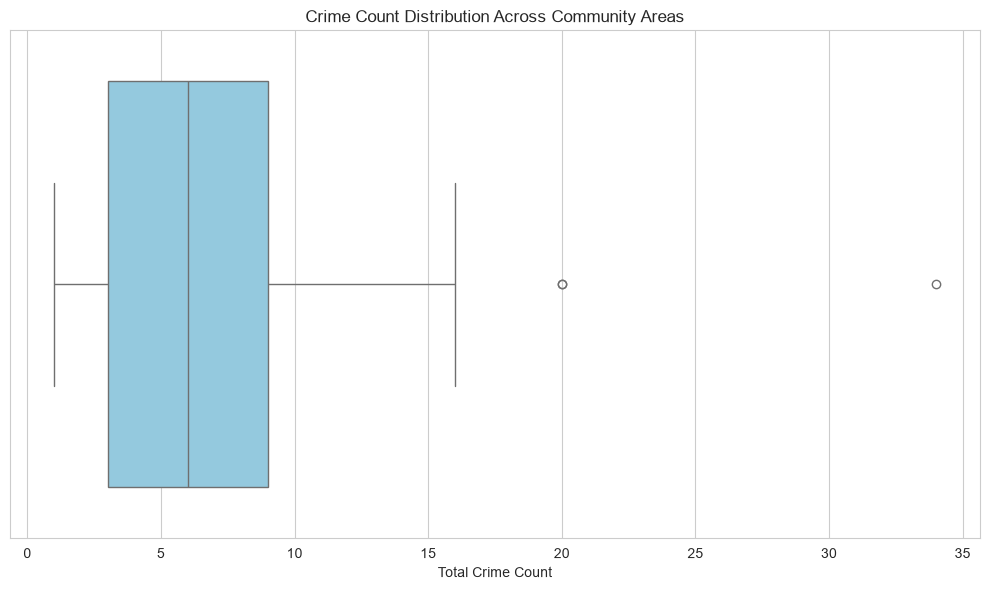

In [109]:

# Use Case 3.2 - Community Area Statistical Analysis

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate crime counts per community area
community_crimes = (
    df.dropna(subset=['community_code'])
    .groupby('community_code')
    .size()
    .reset_index(name='total_crimes')
)

# Extract crime counts as NumPy array
crime_counts = community_crimes['total_crimes'].to_numpy()

# Calculate statistical values
mean_crimes = np.mean(crime_counts)
median_crimes = np.median(crime_counts)

q1 = np.percentile(crime_counts, 25)
q3 = np.percentile(crime_counts, 75)

iqr = q3 - q1

# Calculate IQR boundaries
lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)

# Identify outliers
outliers = community_crimes[
    (community_crimes['total_crimes'] < lower_bound) |
    (community_crimes['total_crimes'] > upper_bound)
]

# Display statistical summary
print("Community Area Statistical Summary")
print("-" * 40)

print("Total Community Areas:", len(community_crimes))
print("Mean Crime Count:", round(mean_crimes, 2))
print("Median Crime Count:", round(median_crimes, 2))
print("Q1:", round(q1, 2))
print("Q3:", round(q3, 2))
print("IQR:", round(iqr, 2))
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))

# Display outliers
print("\nExtreme Crime Count Outliers:")
display(outliers)

# Box plot
plt.figure(figsize=(10, 6))

sns.boxplot(
    x=crime_counts,
    color='skyblue'
)

plt.title('Crime Count Distribution Across Community Areas')
plt.xlabel('Total Crime Count')

plt.tight_layout()
plt.show()


Crime Correlation Matrix
----------------------------------------


,year,Month,arrest,domestic,beat_num,district_code,ward_no,community_code
year,1.00,0.15,-0.13,0.02,-0.13,-0.13,-0.06,0.09
Month,0.15,1.00,-0.18,0.03,-0.10,-0.10,-0.05,0.01
arrest,-0.13,-0.18,1.00,0.01,0.02,0.02,0.03,-0.06
domestic,0.02,0.03,0.01,1.00,-0.01,-0.01,-0.00,0.01
beat_num,-0.13,-0.10,0.02,-0.01,1.00,1.00,0.72,-0.47
district_code,-0.13,-0.10,0.02,-0.01,1.00,1.00,0.72,-0.47
ward_no,-0.06,-0.05,0.03,-0.00,0.72,0.72,1.00,-0.55
community_code,0.09,0.01,-0.06,0.01,-0.47,-0.47,-0.55,1.00


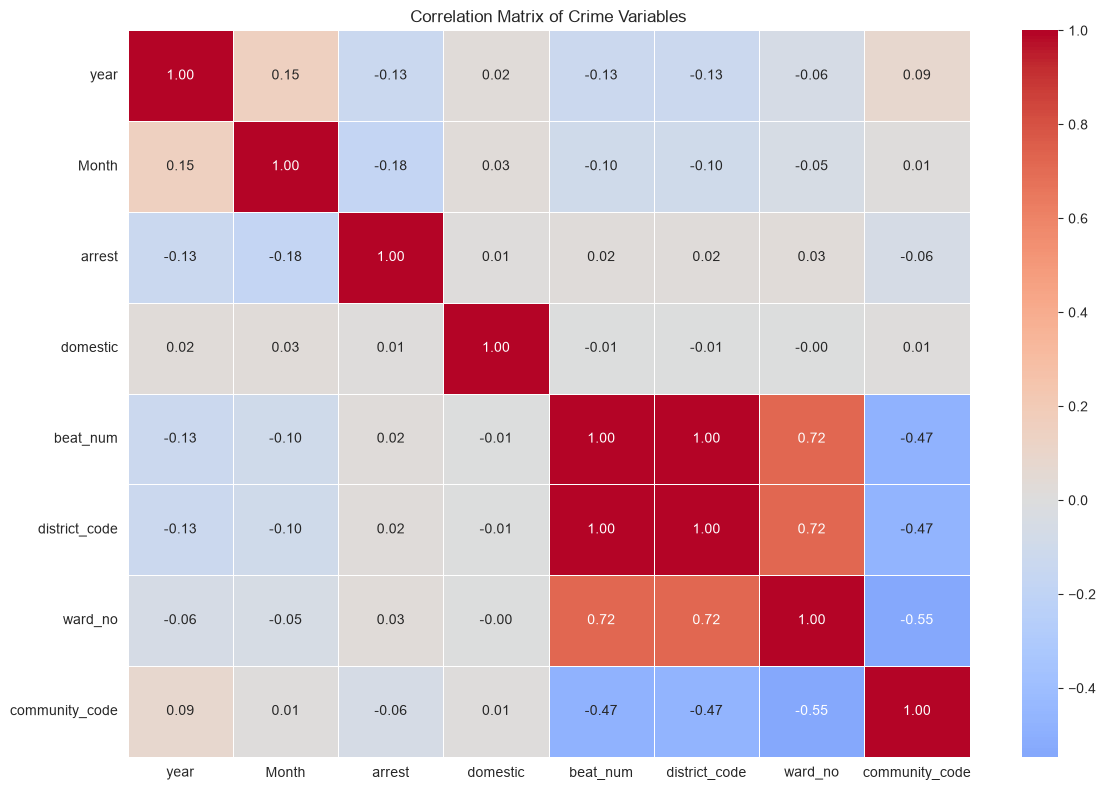

In [110]:

# Use Case 3.3 - Crime Cross-Correlation

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical variables available in the dataset
numerical_columns = [
    'year',
    'Month',
    'arrest',
    'domestic',
    'beat_num',
    'district_code',
    'ward_no',
    'community_code'
]

# Keep only columns present in the dataframe
numerical_columns = [
    col for col in numerical_columns
    if col in df.columns
]

# Convert selected columns to numeric
correlation_df = df[numerical_columns].apply(
    pd.to_numeric,
    errors='coerce'
)

# Remove columns with no variation or entirely missing values
correlation_df = correlation_df.loc[
    :,
    correlation_df.nunique(dropna=True) > 1
]

# Calculate correlation matrix
correlation_matrix = correlation_df.corr()

print("Crime Correlation Matrix")
print("-" * 40)

display(correlation_matrix.round(2))

# Visualize correlation matrix
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Correlation Matrix of Crime Variables')
plt.tight_layout()
plt.show()


In [107]:
print("FINAL PROJECT EXPORTS\n")

for root, dirs, files in os.walk(reports_dir):
    for file in files:
        file_path = os.path.join(root, file)
        print(
            os.path.relpath(file_path, reports_dir),
            "-",
            round(os.path.getsize(file_path) / 1024, 2),
            "KB"
        )

FINAL PROJECT EXPORTS

chicago_crime.db - 108.0 KB
chicago_crime_cleaned.csv - 108.88 KB
analysis_results\arrest_analysis.csv - 0.62 KB
analysis_results\arrest_summary.csv - 0.05 KB
analysis_results\community_analysis.csv - 0.95 KB
analysis_results\district_analysis.csv - 0.36 KB
analysis_results\domestic_arrest.csv - 0.09 KB
analysis_results\domestic_summary.csv - 0.07 KB
analysis_results\final_summary.csv - 0.13 KB
analysis_results\hotspots.csv - 7.88 KB
analysis_results\location_summary.csv - 0.23 KB
analysis_results\monthly_crimes.csv - 0.05 KB
analysis_results\top_crimes.csv - 0.25 KB
analysis_results\top_districts.csv - 0.12 KB
analysis_results\weekday_summary.csv - 0.11 KB
analysis_results\yearly_summary.csv - 0.1 KB
analysis_results\year_month_crimes.csv - 0.14 KB
